# Projeto 3 — Variational Autoencoder (VAE)

In [65]:
import os
import random
from pathlib import Path
from importlib.metadata import version

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import MNIST
from ucimlrepo import fetch_ucirepo

import json
import hashlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
import gc
import pickle
import optuna
from types import SimpleNamespace
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from umap import UMAP
from sklearn.manifold import TSNE

DATA_DIR = Path("../data/raw").resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def configurar_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

configurar_seed()
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
print(f"Dispositivo: {DEVICE}")


Dispositivo: cuda


## Dataset 1: Dry Bean
[Fonte: UCI Machine Learning Repository, ID 602](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset). São 13.611 amostras, 16 atributos numéricos e 7 classes de feijão.

In [66]:
dry_bean_path = DATA_DIR / "dry_bean.csv"
if dry_bean_path.exists():
    dry_bean_df = pd.read_csv(dry_bean_path)
else:
    dry_bean = fetch_ucirepo(id=602)
    dry_bean_df = pd.concat([dry_bean.data.features, dry_bean.data.targets], axis=1)
    dry_bean_df.to_csv(dry_bean_path, index=False)

X_dry_bean = dry_bean_df.drop(columns="Class").copy()
y_dry_bean = dry_bean_df["Class"].copy()

print(f"Dry Bean: {X_dry_bean.shape[0]} amostras, {X_dry_bean.shape[1]} atributos")
display(X_dry_bean.head())
display(y_dry_bean.value_counts().sort_index().rename("amostras").to_frame())


Dry Bean: 13611 amostras, 16 atributos


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


,amostras
Class,
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1928
SEKER,2027
SIRA,2636


## Pré-processamento do dataset Dry Bean

Verificamos ausentes e retiramos duplicatas. Dividimos em treino, validação e teste com estratificação e seed fixa. A tabela compara as porcentagens de cada classe. Padronizamos os atributos usando somente o treino.

In [67]:
#Conferir ausentes e retirar duplicatas antes da divisão.
print("Valores ausentes no Dry Bean:", dry_bean_df.isna().sum().sum())
dry_clean = dry_bean_df.drop_duplicates()
print("Duplicatas removidas:", len(dry_bean_df) - len(dry_clean))

#Dry Bean: 70% treino, 15% validação e 15% teste.
X_dry_train, X_dry_test, y_dry_train, y_dry_test = train_test_split(dry_clean.drop(columns="Class"), dry_clean["Class"],test_size=0.15, stratify=dry_clean["Class"], random_state=SEED)
X_dry_train, X_dry_val, y_dry_train, y_dry_val = train_test_split(X_dry_train, y_dry_train,test_size=0.15 / 0.85, stratify=y_dry_train, random_state=SEED)

#Padronização dos dados (StandardScaler) para o Dry Bean.
scaler_dry = StandardScaler()
X_dry_train = scaler_dry.fit_transform(X_dry_train).astype("float32")
X_dry_val = scaler_dry.transform(X_dry_val).astype("float32")
X_dry_test = scaler_dry.transform(X_dry_test).astype("float32")


def conferir_classes(y_train, y_val, y_test):
    conjuntos = {"treino": y_train, "validação": y_val, "teste": y_test}
    print("Amostras:", {nome: len(y) for nome, y in conjuntos.items()})
    display(pd.DataFrame({nome: pd.Series(y).value_counts(normalize=True) * 100 for nome, y in conjuntos.items()}).sort_index().round(2).rename_axis("classe (%)"))

conferir_classes(y_dry_train, y_dry_val, y_dry_test)

Valores ausentes no Dry Bean: 0
Duplicatas removidas: 68
Amostras: {'treino': 9479, 'validação': 2032, 'teste': 2032}


,treino,validação,teste
classe (%),,,
BARBUNYA,9.77,9.74,9.74
BOMBAY,3.86,3.84,3.84
CALI,12.03,12.06,12.06
DERMASON,26.18,26.18,26.18
HOROZ,13.74,13.73,13.73
SEKER,14.97,14.96,14.96
SIRA,19.45,19.49,19.49


## Dataset 2: MNIST
[Fonte: MNIST pelo torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html). São imagens de dígitos de 0 a 9, em tons de cinza, com 28 × 28 pixels. Preservamos a divisão oficial: 60.000 imagens para treino e 10.000 para teste.

In [68]:
mnist_train = MNIST(root=str(DATA_DIR), train=True, download=True)
mnist_test = MNIST(root=str(DATA_DIR), train=False, download=True)
X_mnist_train, y_mnist_train = mnist_train.data.numpy(), mnist_train.targets.numpy()
X_mnist_test, y_mnist_test = mnist_test.data.numpy(), mnist_test.targets.numpy()

print(f"MNIST treino: {X_mnist_train.shape}, rótulos: {y_mnist_train.shape}")
print(f"MNIST teste: {X_mnist_test.shape}, rótulos: {y_mnist_test.shape}")

MNIST treino: (60000, 28, 28), rótulos: (60000,)
MNIST teste: (10000, 28, 28), rótulos: (10000,)


## Pré-processamento do MNIST

Preservamos as 10.000 imagens de teste oficiais e dividimos as 60.000 restantes em 50.000 de treino e 10.000 de validação. Normalizamos os pixels para [0, 1] em float32 e mantemos o formato 28 × 28.

In [69]:
#Separar 10.000 imagens para validação e manter o teste oficial intacto.
X_mnist_train_split, X_mnist_val, y_mnist_train_split, y_mnist_val = train_test_split(X_mnist_train, y_mnist_train,test_size=1/6, stratify=y_mnist_train, random_state=SEED)

#Normalizar os dados do MNIST para o intervalo [0, 1].
X_mnist_train_norm = X_mnist_train_split.astype("float32") / 255.0
X_mnist_val_norm = X_mnist_val.astype("float32") / 255.0
X_mnist_test_norm = X_mnist_test.astype("float32") / 255.0

conferir_classes(y_mnist_train_split, y_mnist_val, y_mnist_test)

Amostras: {'treino': 50000, 'validação': 10000, 'teste': 10000}


,treino,validação,teste
classe (%),,,
0,9.87,9.87,9.80
1,11.24,11.24,11.35
2,9.93,9.93,10.32
3,10.22,10.22,10.10
4,9.74,9.74,9.82
5,9.04,9.03,8.92
6,9.86,9.86,9.58
7,10.44,10.44,10.28
8,9.75,9.75,9.74


## Implementação do VAE

- **Encoder:** resume os dados em uma representação menor, chamada espaço latente.
- **Amostragem:** adiciona uma variação aleatória ao resumo produzido pelo encoder.
- **Decoder:** usa esse resumo para tentar reconstruir os dados originais.
- **Custo:** mede o erro da reconstrução e ajuda a organizar o espaço latente (termo KL).

O **MSE (erro quadrático médio)** mede a distância entre os valores originais e os reconstruídos, penalizando mais os erros grandes. Ele serve tanto para reconstruir as medidas do Dry Bean quanto as intensidades dos pixels do MNIST.

Usamos, portanto, o mesmo critério de reconstrução nos dois datasets. A saída do decoder continua **linear no Dry Bean**, para permitir valores negativos após a padronização, e **sigmoid no MNIST**, para manter os pixels entre 0 e 1.

In [ ]:
class Encoder(nn.Module):
    def __init__(self, input_shape, latent_dim, camadas, ativacao):
        super().__init__()
        entrada = int(np.prod(input_shape))
        partes = [nn.Flatten()]
        for unidades in camadas:
            partes += [nn.Linear(entrada, unidades), ativacao()]
            entrada = unidades
        self.rede = nn.Sequential(*partes)
        self.z_mean = nn.Linear(entrada, latent_dim)
        self.z_log_var = nn.Linear(entrada, latent_dim)

    def forward(self, inputs):
        x = self.rede(inputs)
        return self.z_mean(x), self.z_log_var(x)

class VAE(nn.Module):
    def __init__(self, encoder, decoder, peso_kl=1.0):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.peso_kl = peso_kl

    #Função de chamada do modelo, que define o fluxo de dados através do encoder e decoder.
    def forward(self, inputs, amostrar=True):
        #O encoder produz a média e o logaritmo da variância do resumo.
        z_mean, z_log_var = self.encoder(inputs)

        #Amostragem: combina a média, o desvio e um ruído aleatório.
        z = z_mean + torch.exp(0.5 * z_log_var) * torch.randn_like(z_mean) if amostrar else z_mean

        #O decoder tenta recuperar a entrada a partir do resumo z.
        return self.decoder(z), z_mean, z_log_var

def criar_vae(input_shape, latent_dim=2, camadas=(64, 32), tipo="tabular",
              learning_rate=1e-3, ativacao="relu", otimizador="Adam", peso_kl=1.0):
    #Cria a rede.
    ativacoes = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}
    if tipo not in ("tabular", "imagem"):
        raise ValueError("tipo deve ser 'tabular' ou 'imagem'.")
    if ativacao not in ativacoes or otimizador not in ("Adam", "RMSprop", "SGD"):
        raise ValueError("Ativação ou otimizador não suportado.")
    if peso_kl < 0:
        raise ValueError("O peso KL deve ser não negativo.")
    input_shape = tuple(input_shape)

    #Encoder: transforma a entrada em um resumo menor.
    encoder = Encoder(input_shape, latent_dim, camadas, ativacoes[ativacao])

    #Decoder: percorre as camadas na ordem inversa e reconstrói a entrada.
    partes, entrada = [], latent_dim
    for unidades in reversed(camadas):
        partes += [nn.Linear(entrada, unidades), ativacoes[ativacao]()]
        entrada = unidades
    partes.append(nn.Linear(entrada, int(np.prod(input_shape))))

    #Sigmoid limita pixels a [0, 1], já o linear permite valores negativos no Dry Bean.
    if tipo == "imagem":
        partes.append(nn.Sigmoid())

    #Recupera o formato original: 16 atributos ou imagem 28 × 28.
    partes.append(nn.Unflatten(1, input_shape))
    vae = VAE(encoder, nn.Sequential(*partes), peso_kl).to(DEVICE)

    #Junta as partes e escolhe o otimizador que ajustará os pesos.
    classe_otimizador = getattr(torch.optim, otimizador)
    opcoes = {"momentum": 0.9} if otimizador == "SGD" else {}
    vae.optimizer = classe_otimizador(vae.parameters(), lr=learning_rate, **opcoes)
    vae.configuracao = dict(input_shape=list(input_shape), latent_dim=latent_dim,
                           camadas=list(camadas), tipo=tipo, learning_rate=learning_rate,
                           ativacao=ativacao, otimizador=otimizador, peso_kl=peso_kl)
    return vae

#Treina o VAE com os dados de treino e validação, salvando histórico e pesos se desejado.
def treinar_vae(vae, X_train, X_val, epochs=100, batch_size=128, patience=10,
                nome="vae", salvar=True, diretorio=None, verbose=1):
    if epochs < 1 or patience < 1:
        raise ValueError("epochs e patience devem ser positivos.")
    dispositivo = next(vae.parameters()).device
    gerador = torch.Generator().manual_seed(torch.initial_seed())
    loaders = {
        "": DataLoader(TensorDataset(torch.as_tensor(X_train, dtype=torch.float32)),
                       batch_size=batch_size, shuffle=True, generator=gerador),
        "val_": DataLoader(TensorDataset(torch.as_tensor(X_val, dtype=torch.float32)),
                           batch_size=batch_size, shuffle=False),
    }
    nomes = ("loss", "reconstruction_loss", "kl_loss", "score")
    historico = {prefixo + chave: [] for prefixo in loaders for chave in nomes}
    melhor_score, sem_melhora, melhores_pesos = float("inf"), 0, None
    if salvar:
        resultados = Path(diretorio) if diretorio is not None else DATA_DIR.parents[1] / "results"
        (resultados / "historicos").mkdir(parents=True, exist_ok=True)
        (resultados / "modelos").mkdir(parents=True, exist_ok=True)
        execucao = f"{nome}_{pd.Timestamp.now():%Y%m%d_%H%M%S_%f}"
        arquivo = resultados / "historicos" / f"{execucao}.csv"
        pesos = resultados / "modelos" / f"{execucao}.pt"

    for epoca in range(epochs):
        for prefixo, loader in loaders.items():
            treino = prefixo == ""
            vae.train(treino)
            totais = np.zeros(4, dtype=np.float64)
            with torch.set_grad_enabled(treino):
                for (lote,) in loader:
                    lote = lote.to(dispositivo)
                    if treino:
                        vae.optimizer.zero_grad(set_to_none=True)
                    reconstruido, z_mean, z_log_var = vae(lote, amostrar=treino)
                    #O erro quadrático médio (MSE) mede a diferença entre a entrada e a reconstrução.
                    recon_loss = (lote - reconstruido).flatten(1).square().sum(1).mean()
                    #KL: incentiva o espaço latente a seguir uma normal padrão.
                    kl_loss = -0.5 * (1 + z_log_var - z_mean.square() - z_log_var.exp()).sum(1).mean()
                    loss = recon_loss + vae.peso_kl * kl_loss
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Perda não finita durante o treinamento.")
                    if treino:
                        loss.backward()
                        vae.optimizer.step()
                    # Critério comum para comparar pesos KL diferentes, sem favorecer pesos menores.
                    score = recon_loss + kl_loss
                    totais += np.array([v.detach().item() for v in (loss, recon_loss, kl_loss, score)]) * len(lote)
            for chave, valor in zip(nomes, totais / len(loader.dataset)):
                historico[prefixo + chave].append(float(valor))

        if historico["val_score"][-1] < melhor_score:
            melhor_score, sem_melhora = historico["val_score"][-1], 0
            melhores_pesos = {k: v.detach().cpu().clone() for k, v in vae.state_dict().items()}
            if salvar:
                torch.save(melhores_pesos, pesos)
        else:
            sem_melhora += 1
        if salvar:
            pd.DataFrame(historico).rename_axis("epoch").to_csv(arquivo)
        if verbose:
            print(f"Época {epoca + 1}/{epochs} — loss: {historico['loss'][-1]:.4f} — val_score: {historico['val_score'][-1]:.4f}")
        if sem_melhora >= patience:
            break

    vae.load_state_dict(melhores_pesos)
    vae.eval()
    if salvar:
        print(f"Perdas salvas em: {arquivo}")
        print(f"Melhores pesos salvos em: {pesos}")
    return SimpleNamespace(history=historico)

@torch.inference_mode()
def prever_em_lotes(vae, X, parte="encoder", batch_size=512):
    vae.eval()
    dispositivo = next(vae.parameters()).device
    loader = DataLoader(TensorDataset(torch.as_tensor(X, dtype=torch.float32)), batch_size=batch_size)
    saidas = []
    for (lote,) in loader:
        saida = vae.encoder(lote.to(dispositivo))[0] if parte == "encoder" else vae.decoder(lote.to(dispositivo))
        saidas.append(saida.cpu().numpy())
    return np.concatenate(saidas)

def codificar(vae, X):
    return prever_em_lotes(vae, X, parte="encoder")


def decodificar(vae, z):
    return prever_em_lotes(vae, z, parte="decoder")

## Otimização de Hiperparâmetros — Optuna

Cada trial testa 1–3 camadas, 16/32/64/128 neurônios por camada, learning rate de **1e-5 a 1e-2** (log), batch size 64/128/256, ativação ReLU/Tanh/LeakyReLU, otimizador Adam/RMSprop/SGD (momentum 0,9 no SGD) e peso KL **0,1/0,5/1/2**. São **30 trials por dimensão**, com até **100 épocas e patience 10 no Dry Bean** e **50 épocas e patience 7 no MNIST**, para reduzir o tempo. A dimensão latente fica fixa e o teste não participa da busca.

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

ESPACO_BUSCA = {
    "n_camadas": [1, 3],
    "neuronios": [16, 32, 64, 128],
    "learning_rate": [1e-5, 1e-2],
    "batch_size": [64, 128, 256],
    "ativacao": ["relu", "tanh", "leaky_relu"],
    "otimizador": ["Adam", "RMSprop", "SGD"],
    "peso_kl": [0.1, 0.5, 1.0, 2.0],
}

def resumir_trials(study, n=5):
    #Ordenar apenas os trials concluídos pela menor perda de validação.
    config = study.user_attrs["experimento"]
    entrada = int(np.prod(config["input_shape"]))
    latente = config["latent_dim"]
    trials = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
    trials = sorted((t for t in trials if t.value is not None and np.isfinite(t.value)),key=lambda t: (t.value, t.number))[:n]
    linhas = []
    for trial in trials:
        camadas = trial.user_attrs["camadas"]
        linhas.append({
            "latente": latente, "trial": trial.number,
            "encoder": " → ".join(map(str, [entrada, *camadas, latente])),
            "decoder": " → ".join(map(str, [latente, *reversed(camadas), entrada])),
            "learning_rate": trial.params["learning_rate"],
            "batch_size": trial.params["batch_size"],
            "melhor_epoca": trial.user_attrs["melhor_epoca"],
            "ativacao": trial.params["ativacao"],
            "otimizador": trial.params["otimizador"],
            "peso_kl": trial.params["peso_kl"],
            "menor_val_score": trial.value,
        })
    return pd.DataFrame(linhas)

def objective(trial, X_train, X_val, input_shape, tipo, latent_dim, espaco_busca, diretorio, epochs=100, patience=10, seed=42):
    configurar_seed(seed)
    vae = historico = None
    try:
        n = trial.suggest_int("n_camadas", *espaco_busca["n_camadas"])
        camadas = [trial.suggest_categorical(f"neuronios_{i+1}", espaco_busca["neuronios"])for i in range(n)]
        lr = trial.suggest_float("learning_rate", *espaco_busca["learning_rate"], log=True)
        batch = trial.suggest_categorical("batch_size", espaco_busca["batch_size"])
        config = dict(input_shape=list(input_shape), latent_dim=latent_dim,
                      camadas=camadas, tipo=tipo, learning_rate=lr,
                      ativacao=trial.suggest_categorical("ativacao", espaco_busca["ativacao"]),
                      otimizador=trial.suggest_categorical("otimizador", espaco_busca["otimizador"]),
                      peso_kl=trial.suggest_categorical("peso_kl", espaco_busca["peso_kl"]))
        vae = criar_vae(**config)

        historico = treinar_vae(vae, X_train, X_val, epochs=epochs,batch_size=batch, patience=patience, salvar=False, verbose=0)

        perdas = np.asarray(historico.history["val_score"])

        if not np.isfinite(perdas).all():
            raise optuna.TrialPruned("Perda de validação não finita.")
        
        valor = float(perdas.min())
        melhor_epoca = int(perdas.argmin()) + 1
        trial.set_user_attr("camadas", camadas)
        trial.set_user_attr("melhor_epoca", melhor_epoca)
        anteriores = trial.study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
        if not anteriores or valor < min(t.value for t in anteriores):
            pasta = Path(diretorio)
            pasta.mkdir(parents=True, exist_ok=True)
            torch.save(vae.state_dict(), pasta / "melhor_modelo.pt")
            tabela = pd.DataFrame(historico.history).rename_axis("epoch")
            tabela.to_csv(pasta / "melhor_historico.csv")
            resultado = dict(trial=trial.number, val_score=valor, melhor_epoca=melhor_epoca,modelo=config, batch_size=batch, epochs=epochs,patience=patience, seed=seed)
            (pasta / "melhor_configuracao.json").write_text(json.dumps(resultado, indent=2, ensure_ascii=False), encoding="utf-8")
        return valor
    
    except FloatingPointError as erro:
        raise optuna.TrialPruned(str(erro)) from erro
    finally:
        del historico, vae
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()

def otimizar_vae(X_train, X_val, dataset, input_shape, tipo="tabular", latent_dim=2, n_trials=30, espaco_busca=None, diretorio=None, nome_estudo="vae",epochs=100, patience=10, seed=42):
   
    if tuple(X_train.shape[1:]) != tuple(input_shape) or tuple(X_val.shape[1:]) != tuple(input_shape):
        raise ValueError("input_shape deve corresponder ao formato dos dados.")
    if n_trials < 1 or epochs < 1:
        raise ValueError("n_trials e epochs devem ser positivos.")

    espaco = {**ESPACO_BUSCA, **(espaco_busca or {})}
    base = Path(diretorio) if diretorio is not None else DATA_DIR.parents[1] / "results" / "optuna"
    pasta = base / nome_estudo
    pasta.mkdir(parents=True, exist_ok=True)

    def assinatura(X):
        return hashlib.sha256(np.ascontiguousarray(X).view(np.uint8)).hexdigest()

    config = dict(dataset=dataset, input_shape=list(input_shape), tipo=tipo,
                  latent_dim=latent_dim, epochs=epochs, patience=patience, seed=seed,
                  espaco_busca=espaco, treino=list(X_train.shape), validacao=list(X_val.shape),
                  hash_treino=assinatura(X_train), hash_validacao=assinatura(X_val),
                  backend="pytorch", criterio="reconstrucao_mais_kl_1_sem_ruido",
                  device=str(DEVICE), custo="mse_escalado_mais_beta_kl",
                  versoes={p: version(p) for p in ("torch", "torchvision", "optuna", "numpy")})

    config = json.loads(json.dumps(config))
    sampler_path = pasta / "sampler.pkl"

    if sampler_path.exists():
        with sampler_path.open("rb") as f:
            sampler = pickle.load(f)

    else:
        sampler = optuna.samplers.TPESampler(seed=seed)
    study = optuna.create_study(study_name=nome_estudo, direction="minimize", sampler=sampler,storage=f"sqlite:///{(pasta / 'estudo.db').resolve().as_posix()}", load_if_exists=True)
    anterior = study.user_attrs.get("experimento")

    if anterior is not None and anterior != config:
        raise ValueError("Configuração ou dados diferentes: use um novo nome de estudo.")
    study.set_user_attr("experimento", config)

    def salvar_estado(study, trial):
        study.trials_dataframe().to_csv(pasta / "trials.csv", index=False)
        with sampler_path.open("wb") as f:
            pickle.dump(study.sampler, f)

    finalizados = sum(t.state.is_finished() for t in study.trials)
    restantes = max(0, n_trials - finalizados)
    try:
        if restantes:
            study.optimize(lambda trial: objective(trial, X_train, X_val, input_shape, tipo, latent_dim,espaco, pasta, epochs, patience, seed),n_trials=restantes, n_jobs=1, callbacks=[salvar_estado], gc_after_trial=True)
    finally:
        study.trials_dataframe().to_csv(pasta / "trials.csv", index=False)

    display(resumir_trials(study, n=5))
    return study

def carregar_melhor_vae(diretorio):
    pasta = Path(diretorio)
    config = json.loads((pasta / "melhor_configuracao.json").read_text(encoding="utf-8"))
    configurar_seed(config["seed"])
    vae = criar_vae(**config["modelo"])
    vae.load_state_dict(torch.load(pasta / "melhor_modelo.pt", map_location=DEVICE, weights_only=True))
    vae.eval()
    return vae, config


## Experimento 1 — Dry Bean (Latente 2D)

Execução de **30 trials**, cada um com até 100 épocas e patience 10. A tabela mostra os hiperparâmetros selecionados, a menor `val_score` e o número do trial (começando em zero). Serão feitos testes para 2D, 8D, 16D e 32D, utilizando PCA posteriormente para ser possível a visualizaçào em espaços de maior dimensão.

In [72]:
study_dry_2d = otimizar_vae(X_dry_train, X_dry_val, dataset="Dry Bean", input_shape=(16,),tipo="tabular", latent_dim=2, n_trials=30,epochs=100, patience=10, seed=SEED, nome_estudo="dry_bean_2d")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,2,29,16 → 128 → 128 → 2,2 → 128 → 128 → 16,0.001846,256,21,relu,RMSprop,2.0,4.166872
1,2,28,16 → 32 → 128 → 2,2 → 128 → 32 → 16,0.003484,256,58,relu,Adam,1.0,4.211983
2,2,3,16 → 128 → 128 → 2,2 → 128 → 128 → 16,0.001320,128,22,leaky_relu,Adam,1.0,4.251891
3,2,15,16 → 32 → 128 → 2,2 → 128 → 32 → 16,0.003482,64,29,tanh,Adam,1.0,4.325679
4,2,17,16 → 32 → 128 → 2,2 → 128 → 32 → 16,0.003301,64,29,tanh,Adam,1.0,4.342955


In [73]:
pasta_dry_2d = DATA_DIR.parents[1] / "results" / "optuna" / "dry_bean_2d"
vae_dry_2d, config_dry_2d = carregar_melhor_vae(pasta_dry_2d)
historico_dry_2d = pd.read_csv(pasta_dry_2d / "melhor_historico.csv")

### Dry Bean - Latente 8D

In [74]:
study_dry_8d = otimizar_vae(X_dry_train, X_dry_val, dataset="Dry Bean", input_shape=(16,),tipo="tabular", latent_dim=8, n_trials=30,epochs=100, patience=10, seed=SEED, nome_estudo="dry_bean_8d")

pasta_dry_8d = DATA_DIR.parents[1] / "results" / "optuna" / "dry_bean_8d"
vae_dry_8d, config_dry_8d = carregar_melhor_vae(pasta_dry_8d)
historico_dry_8d = pd.read_csv(pasta_dry_8d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,8,3,16 → 128 → 128 → 8,8 → 128 → 128 → 16,0.001320,128,22,leaky_relu,Adam,1.0,3.847056
1,8,23,16 → 16 → 128 → 8,8 → 128 → 16 → 16,0.001256,256,89,leaky_relu,Adam,1.0,3.906341
2,8,26,16 → 128 → 8,8 → 128 → 16,0.000896,256,35,leaky_relu,Adam,1.0,3.924758
3,8,28,16 → 128 → 8,8 → 128 → 16,0.000862,256,35,leaky_relu,Adam,1.0,3.929213
4,8,22,16 → 16 → 128 → 8,8 → 128 → 16 → 16,0.001184,256,89,leaky_relu,Adam,1.0,3.974954


### Dry Bean - Latente 16D

In [75]:
study_dry_16d = otimizar_vae(X_dry_train, X_dry_val, dataset="Dry Bean", input_shape=(16,),tipo="tabular", latent_dim=16, n_trials=30,epochs=100, patience=10, seed=SEED, nome_estudo="dry_bean_16d")

pasta_dry_16d = DATA_DIR.parents[1] / "results" / "optuna" / "dry_bean_16d"
vae_dry_16d, config_dry_16d = carregar_melhor_vae(pasta_dry_16d)
historico_dry_16d = pd.read_csv(pasta_dry_16d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,16,3,16 → 128 → 128 → 16,16 → 128 → 128 → 16,0.001320,128,31,leaky_relu,Adam,1.0,3.779433
1,16,26,16 → 128 → 16,16 → 128 → 16,0.000613,64,31,leaky_relu,Adam,1.0,3.910085
2,16,27,16 → 128 → 16,16 → 128 → 16,0.000549,64,31,relu,Adam,1.0,3.914879
3,16,18,16 → 16 → 128 → 16,16 → 128 → 16 → 16,0.000542,64,98,leaky_relu,Adam,1.0,3.949125
4,16,21,16 → 16 → 128 → 16,16 → 128 → 16 → 16,0.001025,64,63,leaky_relu,Adam,1.0,3.973956


### Dry Bean - Latente 32D

In [76]:
study_dry_32d = otimizar_vae(X_dry_train, X_dry_val, dataset="Dry Bean", input_shape=(16,),tipo="tabular", latent_dim=32, n_trials=30,epochs=100, patience=10, seed=SEED, nome_estudo="dry_bean_32d")

pasta_dry_32d = DATA_DIR.parents[1] / "results" / "optuna" / "dry_bean_32d"
vae_dry_32d, config_dry_32d = carregar_melhor_vae(pasta_dry_32d)
historico_dry_32d = pd.read_csv(pasta_dry_32d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,32,27,16 → 64 → 32,32 → 64 → 16,0.001326,64,36,leaky_relu,Adam,1.0,3.928679
1,32,22,16 → 64 → 32,32 → 64 → 16,0.009743,256,53,leaky_relu,Adam,1.0,3.938789
2,32,3,16 → 128 → 128 → 32,32 → 128 → 128 → 16,0.001320,128,19,leaky_relu,Adam,1.0,3.941035
3,32,21,16 → 64 → 32,32 → 64 → 16,0.004092,256,28,leaky_relu,Adam,1.0,3.946036
4,32,26,16 → 128 → 32,32 → 128 → 16,0.002660,256,43,leaky_relu,Adam,1.0,3.948892


### Resumo dos estudos

In [77]:
estudos_dry = {2: study_dry_2d, 8: study_dry_8d, 16: study_dry_16d, 32: study_dry_32d}
melhores_dry = pd.concat([resumir_trials(study, n=1) for study in estudos_dry.values()],ignore_index=True)
display(melhores_dry)

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,2,29,16 → 128 → 128 → 2,2 → 128 → 128 → 16,0.001846,256,21,relu,RMSprop,2.0,4.166872
1,8,3,16 → 128 → 128 → 8,8 → 128 → 128 → 16,0.001320,128,22,leaky_relu,Adam,1.0,3.847056
2,16,3,16 → 128 → 128 → 16,16 → 128 → 128 → 16,0.001320,128,31,leaky_relu,Adam,1.0,3.779433
3,32,27,16 → 64 → 32,32 → 64 → 16,0.001326,64,36,leaky_relu,Adam,1.0,3.928679


## MNIST — Estudos com latentes 2D, 8D, 16D e 32D

Usamos as mesmas funções e o mesmo espaço de busca do Dry Bean, com **30 trials por dimensão**, até 50 épocas, patience 7 e seed 42. A entrada tem formato **28 × 28** e usa os pixels normalizados. Novamente serão feitos testes nas dimensões: 2D, 8D, 16D e 32D. 

### MNIST - Latente 2D

In [78]:
study_mnist_2d = otimizar_vae(X_mnist_train_norm, X_mnist_val_norm, dataset="MNIST", input_shape=(28, 28),tipo="imagem", latent_dim=2, n_trials=30,epochs=50, patience=7, seed=SEED, nome_estudo="mnist_2d")

pasta_mnist_2d = DATA_DIR.parents[1] / "results" / "optuna" / "mnist_2d"
vae_mnist_2d, config_mnist_2d = carregar_melhor_vae(pasta_mnist_2d)
historico_mnist_2d = pd.read_csv(pasta_mnist_2d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,2,3,784 → 128 → 128 → 2,2 → 128 → 128 → 784,0.001320,128,45,leaky_relu,Adam,1.0,33.682834
1,2,29,784 → 16 → 128 → 2,2 → 128 → 16 → 784,0.001605,128,48,leaky_relu,RMSprop,2.0,36.332641
2,2,21,784 → 32 → 2,2 → 32 → 784,0.002571,64,46,tanh,Adam,1.0,37.680759
3,2,12,784 → 32 → 2,2 → 32 → 784,0.002548,64,34,tanh,Adam,1.0,37.714245
4,2,26,784 → 64 → 2,2 → 64 → 784,0.009270,64,16,tanh,Adam,1.0,37.719112


### MNIST - Latente 8D

In [79]:
study_mnist_8d = otimizar_vae(X_mnist_train_norm, X_mnist_val_norm, dataset="MNIST", input_shape=(28, 28),tipo="imagem", latent_dim=8, n_trials=30,epochs=50, patience=7, seed=SEED, nome_estudo="mnist_8d")

pasta_mnist_8d = DATA_DIR.parents[1] / "results" / "optuna" / "mnist_8d"
vae_mnist_8d, config_mnist_8d = carregar_melhor_vae(pasta_mnist_8d)
historico_mnist_8d = pd.read_csv(pasta_mnist_8d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,8,3,784 → 128 → 128 → 8,8 → 128 → 128 → 784,0.001320,128,49,leaky_relu,Adam,1.0,25.151733
1,8,28,784 → 128 → 8,8 → 128 → 784,0.000905,256,49,tanh,Adam,2.0,26.543571
2,8,14,784 → 128 → 8,8 → 128 → 784,0.002347,64,27,relu,Adam,1.0,26.763054
3,8,24,784 → 64 → 8,8 → 64 → 784,0.000673,64,48,relu,Adam,2.0,27.295734
4,8,23,784 → 64 → 8,8 → 64 → 784,0.000457,64,50,relu,Adam,1.0,27.932639


### MNIST - Latente 16D

In [80]:
study_mnist_16d = otimizar_vae(X_mnist_train_norm, X_mnist_val_norm, dataset="MNIST", input_shape=(28, 28),tipo="imagem", latent_dim=16, n_trials=30,epochs=50, patience=7, seed=SEED, nome_estudo="mnist_16d")

pasta_mnist_16d = DATA_DIR.parents[1] / "results" / "optuna" / "mnist_16d"
vae_mnist_16d, config_mnist_16d = carregar_melhor_vae(pasta_mnist_16d)
historico_mnist_16d = pd.read_csv(pasta_mnist_16d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,16,3,784 → 128 → 128 → 16,16 → 128 → 128 → 784,0.001320,128,49,leaky_relu,Adam,1.0,25.289824
1,16,14,784 → 128 → 16,16 → 128 → 784,0.002347,64,9,relu,Adam,1.0,25.665975
2,16,28,784 → 128 → 16,16 → 128 → 784,0.000681,256,50,tanh,Adam,1.0,26.038317
3,16,22,784 → 64 → 16,16 → 64 → 784,0.000356,64,46,relu,Adam,1.0,26.452785
4,16,23,784 → 64 → 16,16 → 64 → 784,0.000457,64,35,relu,Adam,1.0,26.502897


### MNIST - Latente 32D

In [81]:
study_mnist_32d = otimizar_vae(X_mnist_train_norm, X_mnist_val_norm, dataset="MNIST", input_shape=(28, 28),tipo="imagem", latent_dim=32, n_trials=30,epochs=50, patience=7, seed=SEED, nome_estudo="mnist_32d")

pasta_mnist_32d = DATA_DIR.parents[1] / "results" / "optuna" / "mnist_32d"
vae_mnist_32d, config_mnist_32d = carregar_melhor_vae(pasta_mnist_32d)
historico_mnist_32d = pd.read_csv(pasta_mnist_32d / "melhor_historico.csv")

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,32,3,784 → 128 → 128 → 32,32 → 128 → 128 → 784,0.001320,128,45,leaky_relu,Adam,1.0,24.988985
1,32,14,784 → 128 → 32,32 → 128 → 784,0.002347,64,26,relu,Adam,1.0,25.536177
2,32,28,784 → 128 → 32,32 → 128 → 784,0.000905,256,49,tanh,Adam,1.0,25.797950
3,32,23,784 → 64 → 32,32 → 64 → 784,0.000457,64,45,relu,Adam,1.0,26.664761
4,32,22,784 → 64 → 32,32 → 64 → 784,0.000356,64,47,relu,Adam,1.0,26.765010


### Resumo dos estudos MNIST

Execute depois de concluir as quatro buscas.

In [82]:
estudos_mnist = {2: study_mnist_2d, 8: study_mnist_8d, 16: study_mnist_16d, 32: study_mnist_32d}
melhores_mnist = pd.concat([resumir_trials(study, n=1) for study in estudos_mnist.values()],ignore_index=True)
display(melhores_mnist)

,latente,trial,encoder,decoder,learning_rate,batch_size,melhor_epoca,ativacao,otimizador,peso_kl,menor_val_score
0,2,3,784 → 128 → 128 → 2,2 → 128 → 128 → 784,0.00132,128,45,leaky_relu,Adam,1.0,33.682834
1,8,3,784 → 128 → 128 → 8,8 → 128 → 128 → 784,0.00132,128,49,leaky_relu,Adam,1.0,25.151733
2,16,3,784 → 128 → 128 → 16,16 → 128 → 128 → 784,0.00132,128,49,leaky_relu,Adam,1.0,25.289824
3,32,3,784 → 128 → 128 → 32,32 → 128 → 128 → 784,0.00132,128,45,leaky_relu,Adam,1.0,24.988985


## MSE durante o treinamento — vencedores de cada dimensão

In [83]:
def plotar_mse_vencedores(prefixo, nome, diretorio=None):
    raiz = Path.cwd().resolve()
    if raiz.name == "notebooks":
        raiz = raiz.parent
    base = Path(diretorio) if diretorio is not None else raiz / "results" / "optuna"
    estudos = {}
    for dim in (2, 8, 16, 32):
        pasta = base / f"{prefixo}_{dim}d"
        config_path = pasta / "melhor_configuracao.json"
        history_path = pasta / "melhor_historico.csv"
        if not config_path.exists() or not history_path.exists():
            raise FileNotFoundError(f"Falta o histórico do vencedor de {nome} {dim}D.")
        config = json.loads(config_path.read_text(encoding="utf-8"))
        estudos[dim] = (config, pd.read_csv(history_path))

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    linhas = []
    for ax, (dim, (config, historico)) in zip(axes.flat, estudos.items()):
        n_atributos = int(np.prod(config["modelo"]["input_shape"]))
        epocas = historico["epoch"].to_numpy() + 1
        mse_treino = historico["reconstruction_loss"] / n_atributos
        mse_val = historico["val_reconstruction_loss"] / n_atributos
        # As curvas são do mesmo trial cujos pesos estão salvos como melhor modelo.
        ax.plot(epocas, mse_treino, label="Treino", color="tab:blue")
        ax.plot(epocas, mse_val, label="Validação", color="tab:orange")
        ax.axvline(config["melhor_epoca"], color="gray", linestyle="--",
                   label="Época selecionada")
        ax.set(title=f"Latente {dim}D — trial vencedor {config['trial']}",
               xlabel="Época", ylabel="MSE médio de reconstrução")
        ax.grid(alpha=0.2)
        linhas.append(pd.DataFrame({
            "latente": dim, "trial": config["trial"], "epoca": epocas,
            "mse_treino": mse_treino, "mse_validacao": mse_val,
            "epoca_selecionada": epocas == config["melhor_epoca"],
        }))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3)
    fig.suptitle(f"{nome} — evolução do MSE dos modelos vencedores", fontsize=14)
    fig.tight_layout(rect=(0, 0.05, 1, 0.95))
    pasta_saida = base.parent / "figuras"
    pasta_saida.mkdir(parents=True, exist_ok=True)
    arquivo = pasta_saida / f"{prefixo}_mse_treinamento_vencedores"
    fig.savefig(arquivo.with_suffix(".png"), dpi=200, bbox_inches="tight")
    curvas = pd.concat(linhas, ignore_index=True)
    curvas.to_csv(arquivo.with_suffix(".csv"), index=False)
    plt.show()
    plt.close(fig)
    return curvas

### Dry Bean — MSE dos vencedores 2D, 8D, 16D e 32D

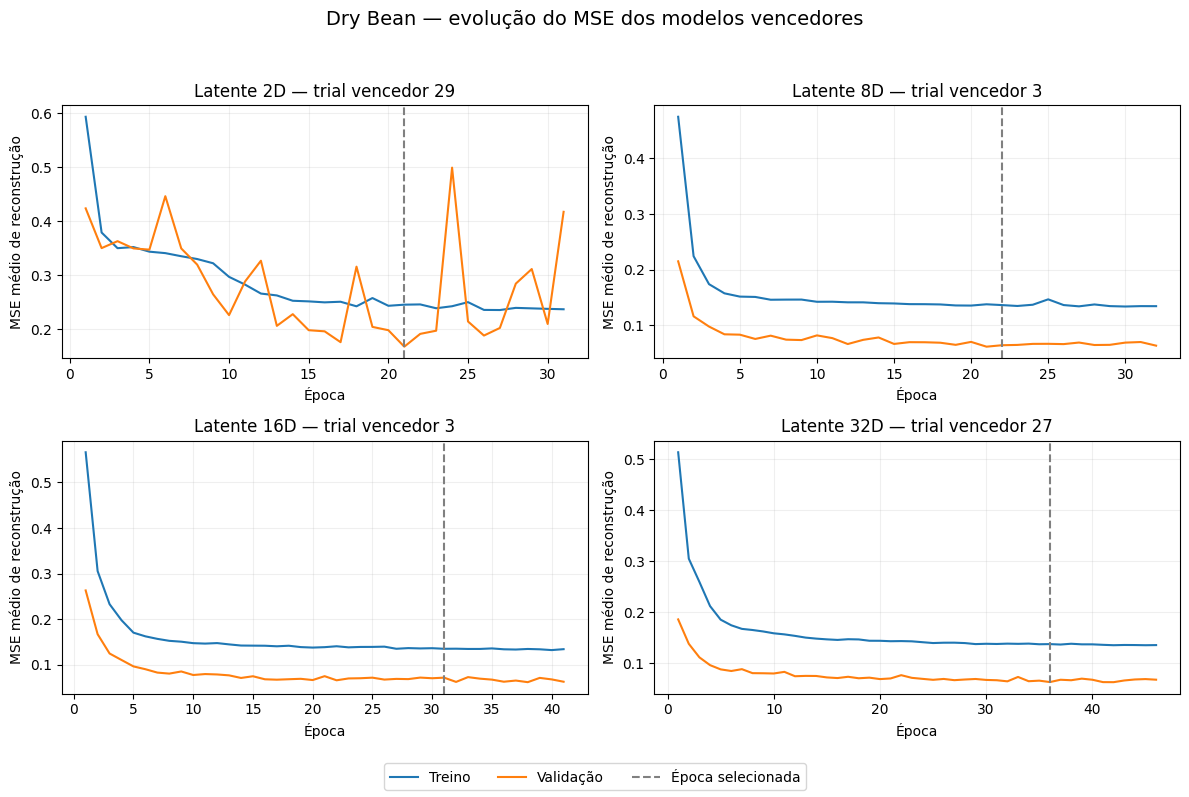

In [84]:
curvas_mse_dry = plotar_mse_vencedores("dry_bean", "Dry Bean")

### MNIST — MSE dos vencedores 2D, 8D, 16D e 32D

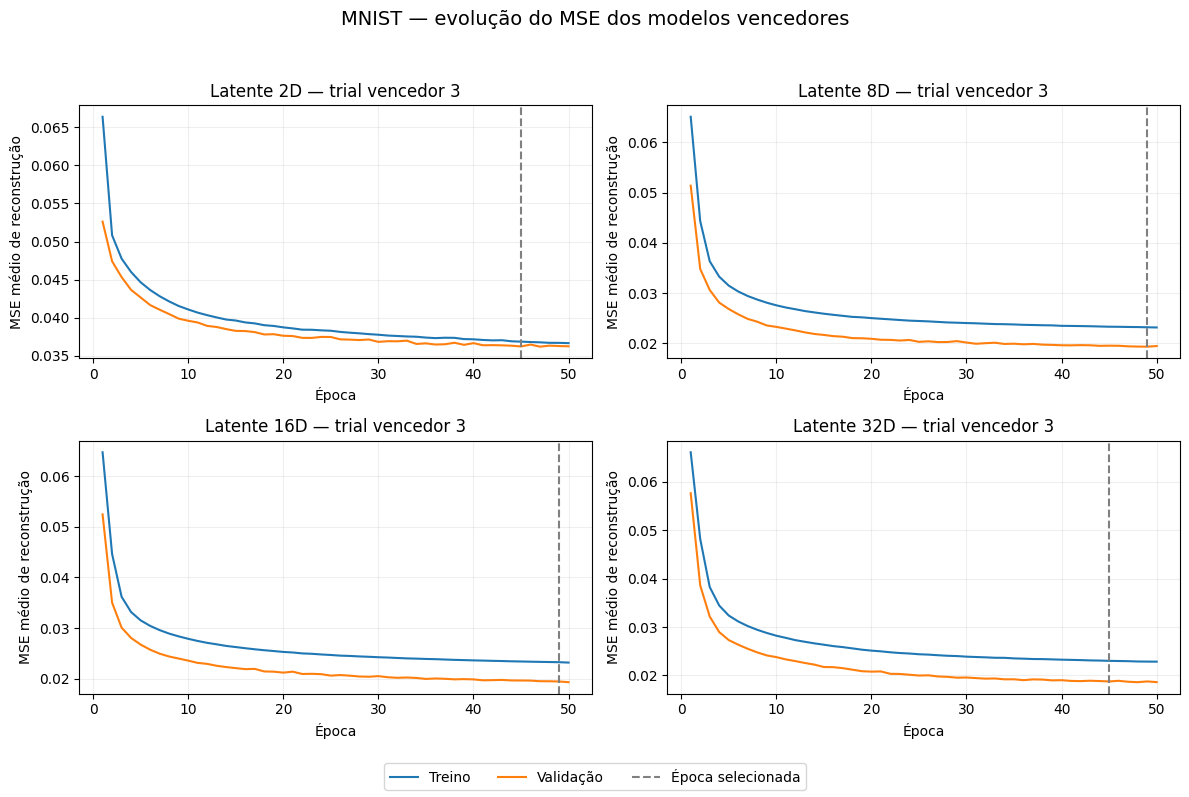

In [85]:
curvas_mse_mnist = plotar_mse_vencedores("mnist", "MNIST")

## Visualização dos espaços latentes — PCA e MSE

Painel comparando os latentes 2D, 8D, 16D e 32D. Foi utilizado o PCA para ser possível a representação dos modelos de dimensão maiores no espaço 2D. PC1 e PC2 indicam a porcentagem da variância de treino preservada.

O PCA procura direções que concentram a maior variação dos latentes de treino: **PC1** captura a maior parcela e **PC2** a maior parcela restante, perpendicular à primeira. Se PC1 explica 45% e PC2 30%, o gráfico preserva 75% da variância; os outros 25% ficam fora das duas coordenadas. Isso ajuda a avaliar quanto da representação aparece na figura e a interpretar sobreposições. Essas porcentagens não são acurácia nem garantem separação das classes; o PCA é ajustado no treino e depois aplicado à validação/teste.

In [86]:
def comparar_latentes(prefixo, nome, X_train, X_eval, y_eval,conjunto="teste", max_pontos=5000):

    rotulo = {"validacao": "validação", "teste": "teste"}[conjunto]
    base = DATA_DIR.parents[1] / "results"
    dimensoes = (2, 8, 16, 32)
    pastas = {d: base / "optuna" / f"{prefixo}_{d}d" for d in dimensoes}
    faltantes = [d for d, p in pastas.items() if not (p / "melhor_modelo.pt").exists()]

    if faltantes:
        raise FileNotFoundError(f"Conclua os estudos de {nome}. Faltam: {faltantes}D")
    y = np.asarray(y_eval)

    if len(X_eval) != len(y):
        raise ValueError("As amostras e os rótulos precisam estar alinhados.")
    
    classes, cores = np.unique(y, return_inverse=True)
    indices = np.arange(len(y))

    if max_pontos is not None and len(y) > max_pontos:
        indices, _ = train_test_split(indices, train_size=max_pontos, stratify=y, random_state=SEED)

    cmap = plt.get_cmap("tab10", len(classes))
    legenda = [Line2D([], [], marker="o", linestyle="", color=cmap(i), label=str(classe))for i, classe in enumerate(classes)]
    pasta_saida = base / "figuras"
    pasta_saida.mkdir(parents=True, exist_ok=True)
    projecoes, linhas, linhas_classe = {}, [], []
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))

    for ax, dim in zip(axes.flat, dimensoes):
        vae, config = carregar_melhor_vae(pastas[dim])
        if config["modelo"]["latent_dim"] != dim:
            raise ValueError(f"A dimensão do modelo salvo não corresponde a {dim}D.")
        
        z_eval = codificar(vae, X_eval)
        reconstruido = decodificar(vae, z_eval)
        erro_quadratico = np.square(np.asarray(X_eval) - reconstruido)
        eixos_atributos = tuple(range(1, erro_quadratico.ndim))
        mse_por_amostra = np.mean(erro_quadratico, axis=eixos_atributos, dtype=np.float64)
        mse = float(np.mean(mse_por_amostra))
        del reconstruido
        pc1 = pc2 = np.nan

        if dim == 2:
            pontos = z_eval
            titulo, eixo_x, eixo_y = "Latente 2D — direto", "z1", "z2"

        else:
            z_train = codificar(vae, X_train)
            pca = PCA(n_components=2, svd_solver="full").fit(z_train)
            pontos = pca.transform(z_eval)
            pc1, pc2 = pca.explained_variance_ratio_ * 100
            titulo = f"Latente {dim}D → PCA 2D ({pc1 + pc2:.1f}% da variância)"
            eixo_x, eixo_y = f"PC1 ({pc1:.1f}%)", f"PC2 ({pc2:.1f}%)"
        projecoes[dim] = pontos
        linhas.append({"conjunto": conjunto, "latente": dim, "MSE": mse,"metodo": "Direto" if dim == 2 else "PCA","PC1 (%)": pc1, "PC2 (%)": pc2, "total (%)": pc1 + pc2})
        
        for classe in classes:
            linhas_classe.append({"conjunto": conjunto, "classe": classe,"latente": dim, "MSE": float(np.mean(mse_por_amostra[y == classe]))})
            
        ax.scatter(pontos[indices, 0], pontos[indices, 1], c=cores[indices], cmap=cmap, vmin=-0.5, vmax=len(classes)-0.5, s=10, alpha=0.6, linewidths=0, rasterized=True)
        ax.set(title=titulo, xlabel=eixo_x, ylabel=eixo_y)
        ax.grid(alpha=0.15)
        ax.text(0.5, 1.13, f"MSE: {mse:.6f}", transform=ax.transAxes,ha="center", va="bottom", fontsize=10)

    fig.suptitle(f"{nome} — {rotulo}", fontsize=14)
    fig.legend(handles=legenda, loc="lower center", ncol=min(5, len(classes)), title="Classe")
    fig.tight_layout(rect=(0, 0.10, 1, 0.95))
    fig.savefig(pasta_saida / f"{prefixo}_{conjunto}_latentes_pca.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    resumo = pd.DataFrame(linhas)
    resumo.to_csv(pasta_saida / f"{prefixo}_{conjunto}_mse_pca.csv", index=False)
    resumo_classe = pd.DataFrame(linhas_classe)
    resumo_classe.to_csv(pasta_saida / f"{prefixo}_{conjunto}_mse_por_classe.csv", index=False)

    tabela_barras = resumo_classe.pivot(index="classe", columns="latente", values="MSE")
    ax = tabela_barras.plot(kind="bar", figsize=(10, 6), width=0.8)
    ax.set(title=f"{nome} — MSE de reconstrução por classe ({rotulo})",
           xlabel="Classe", ylabel="MSE médio")
    ax.legend(title="Dimensão latente", labels=[f"{d}D" for d in tabela_barras.columns])
    ax.grid(axis="y", alpha=0.2)
    ax.figure.tight_layout()
    ax.figure.savefig(pasta_saida / f"{prefixo}_{conjunto}_mse_por_classe.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)
    display(resumo.round(6))
    
    return projecoes, resumo, resumo_classe

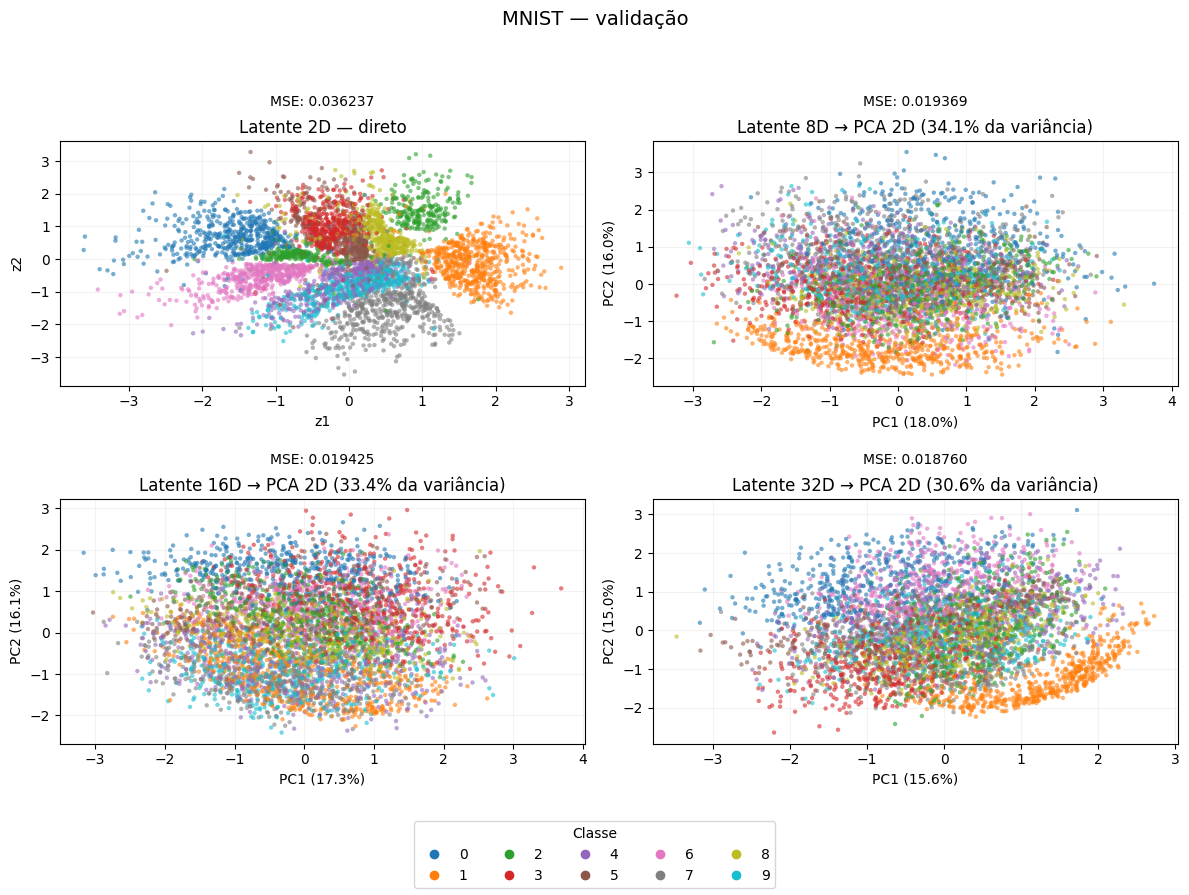

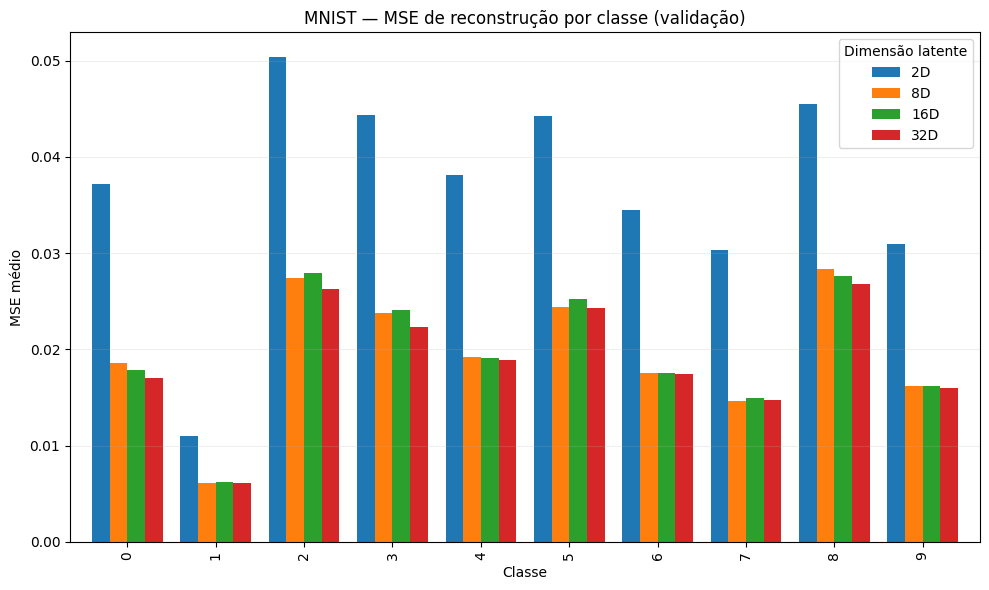

,conjunto,latente,MSE,metodo,PC1 (%),PC2 (%),total (%)
0,validacao,2,0.036237,Direto,NaN,NaN,NaN
1,validacao,8,0.019369,PCA,18.012356,16.040752,34.053108
2,validacao,16,0.019425,PCA,17.255182,16.114109,33.369293
3,validacao,32,0.018760,PCA,15.592461,15.040649,30.633110


In [88]:
projecoes_mnist_val, metricas_mnist_val, mse_classes_mnist_val = comparar_latentes("mnist", "MNIST", X_mnist_train_norm, X_mnist_val_norm, y_mnist_val, conjunto="validacao")

### Teste — Dry Bean

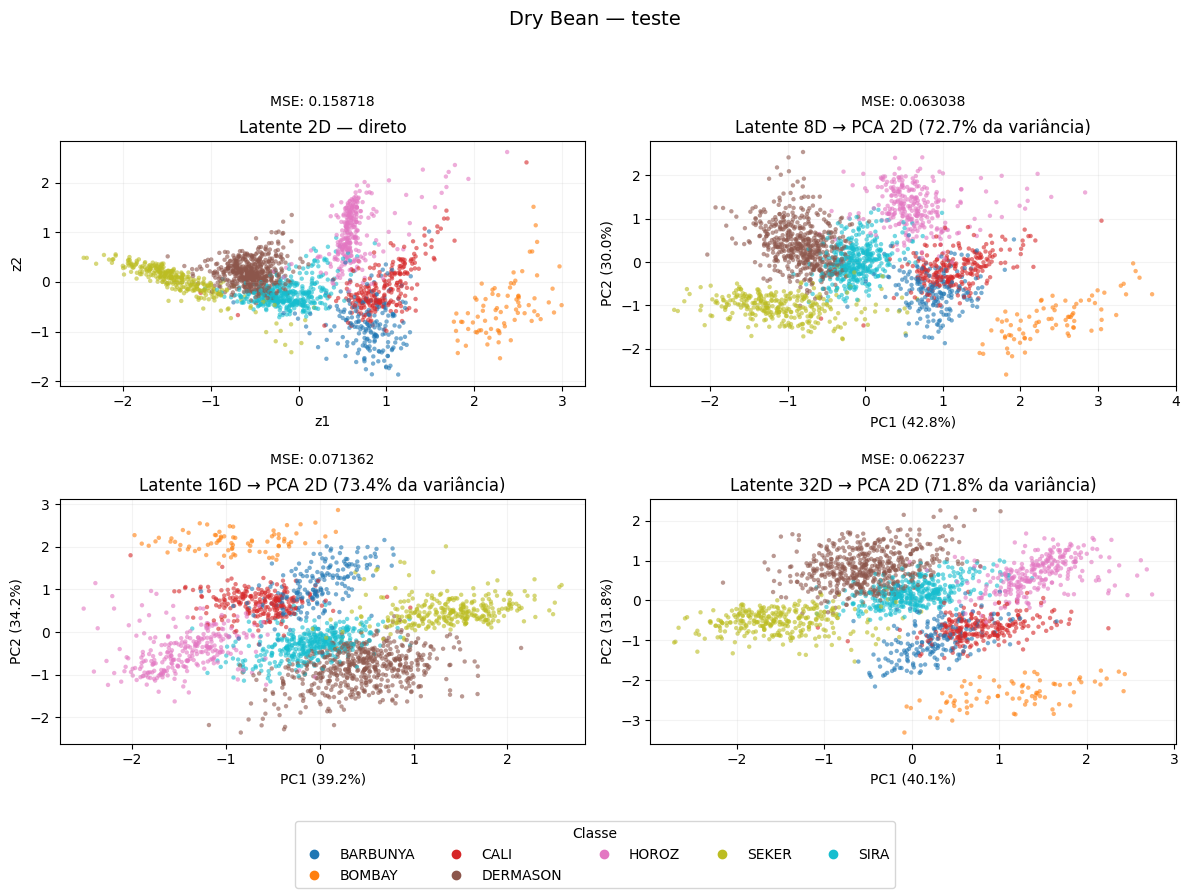

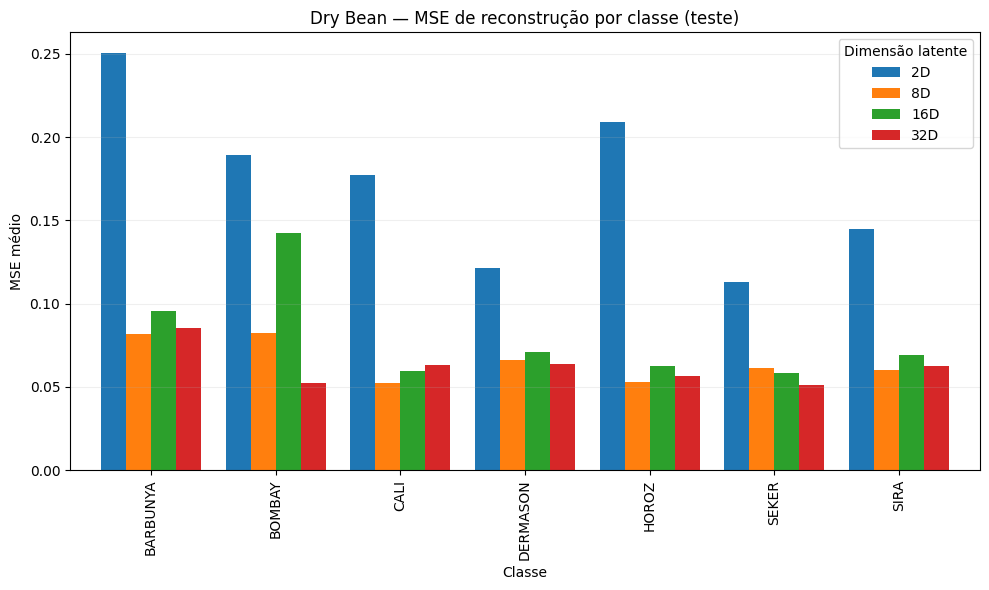

,conjunto,latente,MSE,metodo,PC1 (%),PC2 (%),total (%)
0,teste,2,0.158718,Direto,NaN,NaN,NaN
1,teste,8,0.063038,PCA,42.761681,29.975239,72.736923
2,teste,16,0.071362,PCA,39.178356,34.195309,73.373665
3,teste,32,0.062237,PCA,40.051445,31.798462,71.849907


In [89]:
projecoes_dry, metricas_dry_teste, mse_classes_dry_teste = comparar_latentes("dry_bean", "Dry Bean", X_dry_train, X_dry_test, y_dry_test, conjunto="teste")

### Teste — MNIST

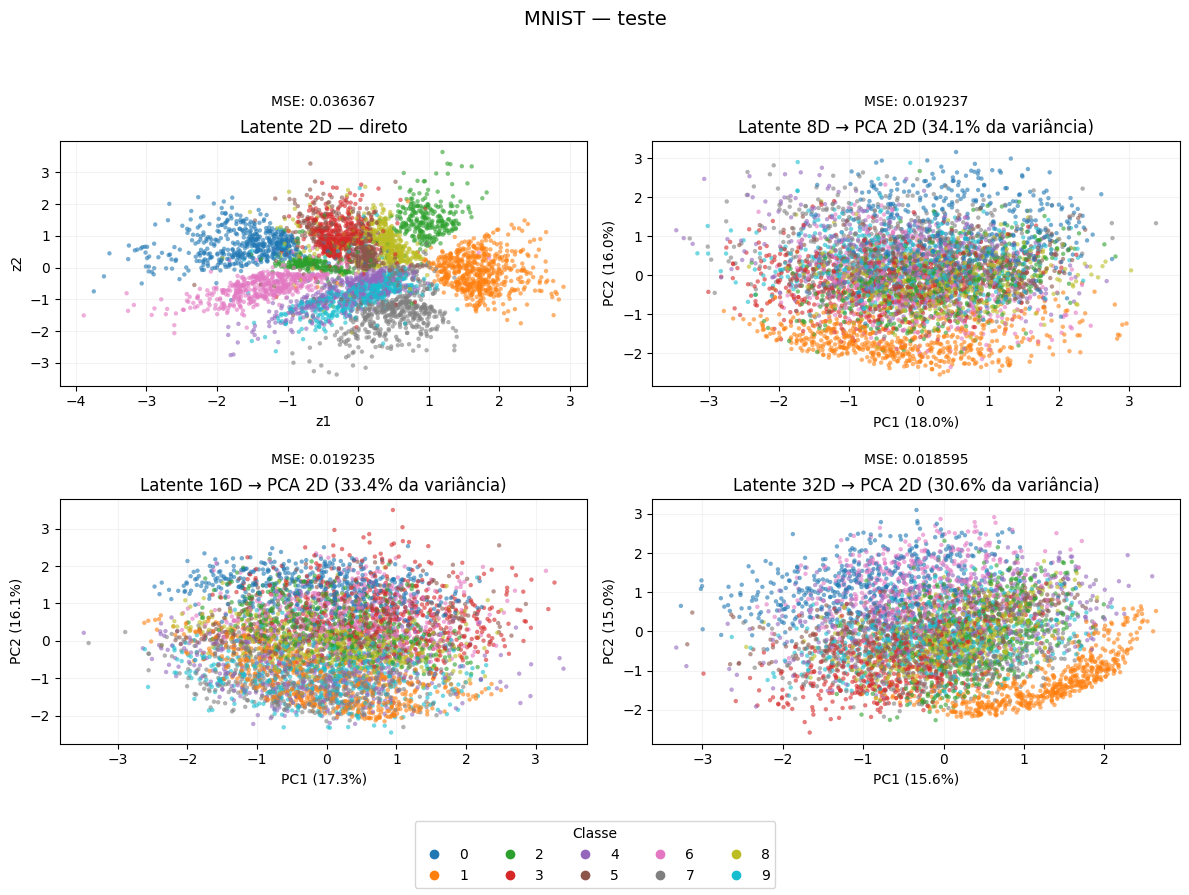

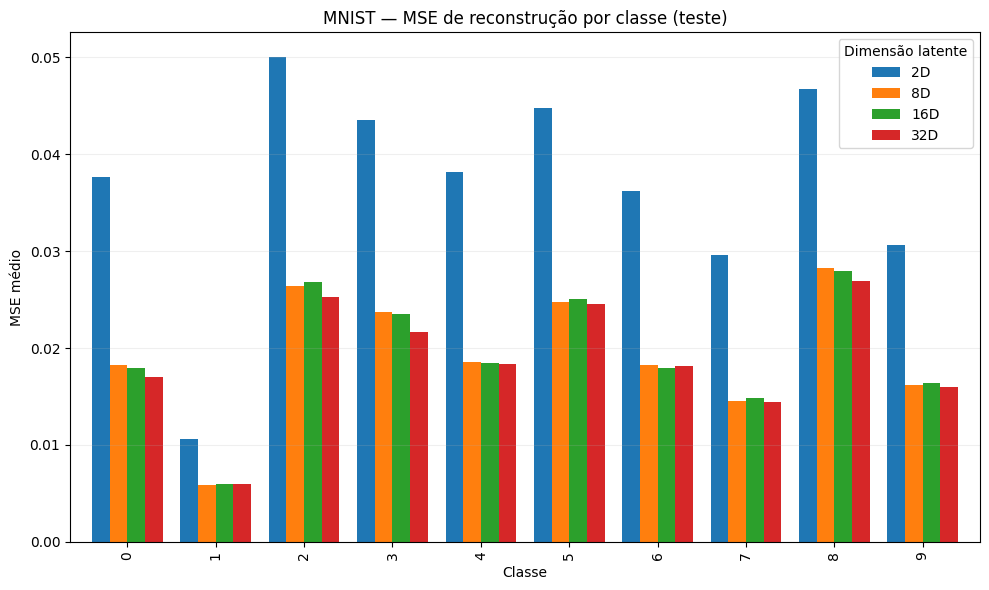

,conjunto,latente,MSE,metodo,PC1 (%),PC2 (%),total (%)
0,teste,2,0.036367,Direto,NaN,NaN,NaN
1,teste,8,0.019237,PCA,18.012356,16.040752,34.053108
2,teste,16,0.019235,PCA,17.255182,16.114109,33.369293
3,teste,32,0.018595,PCA,15.592461,15.040649,30.633110


In [90]:
projecoes_mnist, metricas_mnist_teste, mse_classes_mnist_teste = comparar_latentes("mnist", "MNIST", X_mnist_train_norm, X_mnist_test_norm, y_mnist_test, conjunto="teste")

## Exemplo de reconstrução

Comparamos a primeira instância de teste com as reconstruções dos modelos 2D, 8D, 16D e 32D.

In [91]:
def reconstruir_exemplo(prefixo, X_test, indice=0):
    if not 0 <= indice < len(X_test):
        raise IndexError("Escolha uma posição válida no conjunto de teste.")
    
    original = np.asarray(X_test[indice])
    amostra = original[np.newaxis, ...]
    reconstrucoes, erros = {}, {}
    
    for dim in (2, 8, 16, 32):
        pasta = DATA_DIR.parents[1] / "results" / "optuna" / f"{prefixo}_{dim}d"
        vae, _ = carregar_melhor_vae(pasta)
        z_mean = codificar(vae, amostra)
        reconstruido = decodificar(vae, z_mean)[0]
        reconstrucoes[dim] = reconstruido
        erros[dim] = float(np.mean(np.square(original - reconstruido), dtype=np.float64))
    return original, reconstrucoes, erros

pasta_exemplos = DATA_DIR.parents[1] / "results" / "figuras"
pasta_exemplos.mkdir(parents=True, exist_ok=True)

### MNIST — original e quatro reconstruções

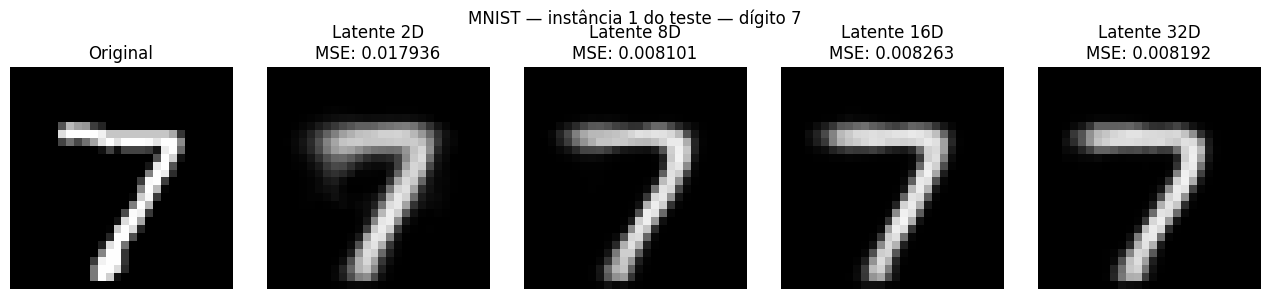

In [92]:
indice = 0
original, reconstrucoes, erros = reconstruir_exemplo(
    "mnist", X_mnist_test_norm, indice
)
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
axes[0].imshow(original, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")
for ax, (dim, imagem) in zip(axes[1:], reconstrucoes.items()):
    ax.imshow(imagem, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Latente {dim}D\nMSE: {erros[dim]:.6f}")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"MNIST — instância {indice + 1} do teste — dígito {y_mnist_test[indice]}")
fig.tight_layout()
fig.savefig(pasta_exemplos / f"mnist_reconstrucao_exemplo_{indice + 1}.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

### Dry Bean — atributos originais e reconstruídos

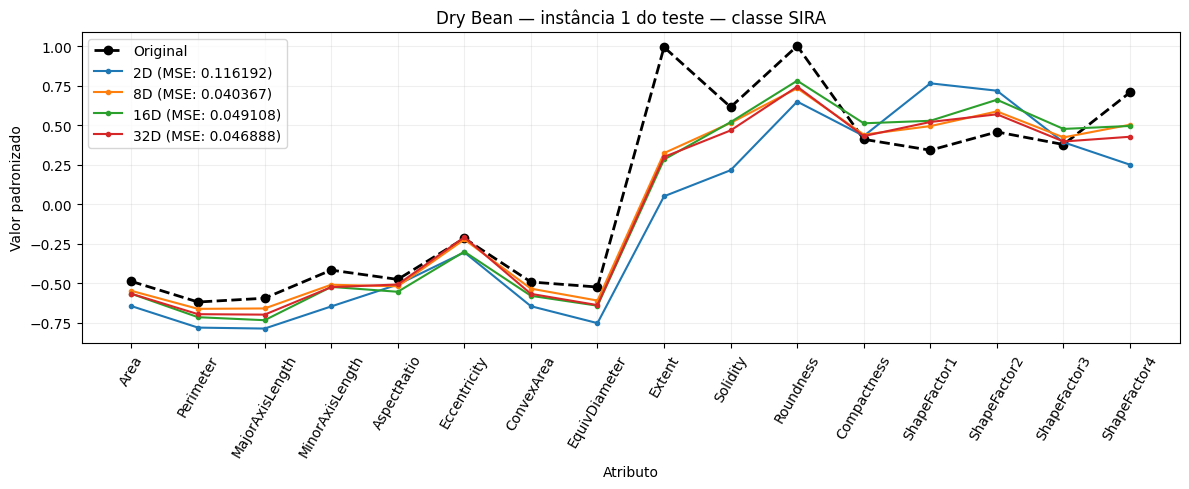

,Original,2D,8D,16D,32D
Area,38660.000000,34051.386719,36894.859375,36350.863281,36350.265625
Perimeter,721.557983,686.704773,712.256714,700.867981,704.996826
MajorAxisLength,268.656097,252.141998,263.088409,256.696106,259.721985
MinorAxisLength,183.564194,173.177002,179.379105,178.765793,178.691895
AspectRatio,1.463600,1.455500,1.452800,1.444300,1.455700
Eccentricity,0.730200,0.722000,0.729500,0.722400,0.730900
ConvexArea,39051.000000,34464.730469,37791.089844,36436.910156,36803.175781
EquivDiameter,221.863602,208.278198,216.769196,214.841705,215.058197
Extent,0.798600,0.752400,0.765700,0.763800,0.764500
Solidity,0.990000,0.988200,0.989500,0.989600,0.989300


In [93]:
indice = 0
original, reconstrucoes, erros = reconstruir_exemplo(
    "dry_bean", X_dry_test, indice
)
atributos = list(X_dry_bean.columns)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(atributos, original, "o--", color="black", label="Original", linewidth=2)
for dim, valores in reconstrucoes.items():
    ax.plot(atributos, valores, ".-", label=f"{dim}D (MSE: {erros[dim]:.6f})")
ax.set(title=f"Dry Bean — instância {indice + 1} do teste — classe {np.asarray(y_dry_test)[indice]}",
       xlabel="Atributo", ylabel="Valor padronizado")
ax.tick_params(axis="x", labelrotation=60)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(pasta_exemplos / f"dry_bean_reconstrucao_exemplo_{indice + 1}.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

valores_originais = scaler_dry.inverse_transform(np.stack([original, *reconstrucoes.values()]))
tabela_exemplo_dry = pd.DataFrame(
    valores_originais.T, index=atributos,
    columns=["Original", *[f"{dim}D" for dim in reconstrucoes]]
)
display(tabela_exemplo_dry.round(4))
tabela_exemplo_dry.to_csv(pasta_exemplos / f"dry_bean_reconstrucao_exemplo_{indice + 1}.csv")

## Análise final dos resultados

### 1. Formação de clusters

**Dry Bean:** há agrupamentos visíveis nas quatro representações, mas nem todos estão completamente separados. BOMBAY forma o grupo mais isolado, enquanto BARBUNYA e CALI aparecem bem próximas um do outro. Esse padrão aparece tanto na validação quanto no teste.

**MNIST:** o latente 2D apresenta regiões associadas a diferentes dígitos, embora haja mistura no centro. Nas projeções PCA de 8D, 16D e 32D, os pontos ficam bastante sobrepostos, sem dez grupos bem definidos, mesmo obtendo menores MSE. Isso acontece, porque o PCA busca preservar as direções de maior variância dos dados, e não necessariamente aquelas que melhor separam as classes. Como as duas primeiras componentes explicam apenas 34,1%, 33,4% e 30,6% da variância, respectivamente, parte considerável das informações é perdida durante a projeção. 

### 2. Separação das classes

**A separação é parcial.** No Dry Bean, BOMBAY se destaca, enquanto BARBUNYA e CALI apresentam bastante mistura. DERMASON e SIRA também apresentam áreas de sobreposição. No MNIST 2D, os dígitos 0 e 1 ocupam regiões mais distintas, mas várias outras classes se misturam. Nas projeções dos modelos maiores, a separação visual é menos clara. Analisando o 2D é possível visualizar que o 4 e 9 acabam tendo muita sobreposição.

Os rótulos foram usados apenas para identificar as classes nos gráficos. O VAE foi treinado para reconstruir os dados e regularizar o espaço latente, sem um objetivo explícito de separar classes. Portanto, um MSE menor não garante grupos mais separados.

### 3. Variância explicada

A soma de PC1 e PC2 indica a parcela da variância dos latentes de treino preservada pela projeção:

| Dimensão latente → PCA 2D | Dry Bean | MNIST |
| --- | ---: | ---: |
| 8D | 72,74% | 34,05% |
| 16D | 73,37% | 33,37% |
| 32D | 71,85% | 30,63% |

No **Dry Bean**, as duas componentes preservam a maior parte da variância. No **MNIST**, cerca de dois terços ficam fora do gráfico, de modo que diferenças entre classes podem estar em dimensões não exibidas. Esses percentuais são calculados no treino e se repetem nos painéis de validação e teste porque usamos o mesmo PCA.

Esse comportamento da variância justifica a diferença na formação de clusters entre os dois Datasets, já que no Dry Bean é possível visualizar melhor a formação de clusters e a separação ou junção das classes, enquanto por outro lado, no MNIST esses pontos são perceptíveis somente no 2D, já que na projeção muita informação acaba sendo perdida, como demonstrado pelos valores da variância.

## Experimento Adicional — VAE com Supervisão Auxiliar

Comparamos os vencedores salvos com novos VAEs treinados do zero, usando as mesmas divisões, seed, arquitetura, otimizador, batch size, limite de épocas e patience. Como classificador é usado uma MLP simples, com uma camada oculta de 32 neurônios.

**Critério de seleção:** o treinamento minimiza `reconstrução + β × KL + λ × classificação`, mantendo o β vencedor. A melhor época e a parada antecipada usam `val_score = reconstrução + KL`, com peso KL igual a 1 nesse critério e validação sem amostragem, como no VAE original. 

In [94]:
def treinar_auxiliar(config, X_train, y_train, X_val, y_val, n_classes, lambda_aux=1.0):
    if not np.isfinite(lambda_aux) or lambda_aux < 0:
        raise ValueError("lambda_aux deve ser finito e não negativo.")
    configurar_seed(config["seed"])
    vae = criar_vae(**config["modelo"])
    #Inicializa o classificador sem alterar a sequência aleatória do VAE.
    estado_rng = torch.get_rng_state()
    classificador = nn.Sequential(nn.Linear(config["modelo"]["latent_dim"], 32),
                                 nn.ReLU(), nn.Linear(32, n_classes)).to(DEVICE)
    torch.set_rng_state(estado_rng)
    vae.optimizer.add_param_group({"params": classificador.parameters()})
    criterio = nn.CrossEntropyLoss()
    loaders = {
        "": DataLoader(TensorDataset(torch.as_tensor(X_train, dtype=torch.float32),
                                    torch.as_tensor(y_train, dtype=torch.long)),
                       batch_size=config["batch_size"], shuffle=True,
                       generator=torch.Generator().manual_seed(config["seed"])),
        "val_": DataLoader(TensorDataset(torch.as_tensor(X_val, dtype=torch.float32),
                                        torch.as_tensor(y_val, dtype=torch.long)),
                           batch_size=config["batch_size"]),
    }
    nomes = ("loss", "reconstruction_loss", "kl_loss", "classification_loss", "score")
    registros, melhor_score, espera = [], float("inf"), 0
    for epoca in range(config["epochs"]):
        linha = {"epoca": epoca + 1}
        for prefixo, loader in loaders.items():
            treino = prefixo == ""
            vae.train(treino)
            classificador.train(treino)
            totais = np.zeros(len(nomes))
            with torch.set_grad_enabled(treino):
                for x, y in loader:
                    x, y = x.to(DEVICE), y.to(DEVICE)
                    if treino:
                        vae.optimizer.zero_grad(set_to_none=True)
                    reconstruido, media, log_var = vae(x, amostrar=treino)
                    rec = (x - reconstruido).flatten(1).square().sum(1).mean()
                    kl = -0.5 * (1 + log_var - media.square() - log_var.exp()).sum(1).mean()
                    ce = criterio(classificador(media), y)
                    loss = rec + vae.peso_kl * kl + lambda_aux * ce
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Perda não finita no treinamento auxiliar.")
                    if treino:
                        loss.backward()
                        vae.optimizer.step()
                    valores = (loss, rec, kl, ce, rec + kl)
                    totais += np.array([v.detach().item() for v in valores]) * len(x)
            linha.update({prefixo + k: float(v) for k, v in zip(nomes, totais / len(loader.dataset))})
        registros.append(linha)
        #Mesmo critério do VAE original: reconstrução + KL na validação, sem classificação.
        if linha["val_score"] < melhor_score:
            melhor_score, espera, melhor_epoca = linha["val_score"], 0, epoca + 1
            pesos = {"vae": {k: v.detach().cpu().clone() for k, v in vae.state_dict().items()},
                     "classificador": {k: v.detach().cpu().clone() for k, v in classificador.state_dict().items()}}
        else:
            espera += 1
        if espera >= config["patience"]:
            break
    vae.load_state_dict(pesos["vae"])
    classificador.load_state_dict(pesos["classificador"])
    vae.eval()
    classificador.eval()
    return vae, pesos, pd.DataFrame(registros), melhor_epoca

In [95]:
def comparar_auxiliar(baseline, auxiliar, X_train, X_test, y_test, classes, nome, dim, pasta, seed):
    #Mesmas amostras e cores em todos os painéis; MSE usa todo o teste.
    indices = np.arange(len(y_test))
    if len(indices) > 2000:
        indices, _ = train_test_split(indices, train_size=2000, stratify=y_test, random_state=seed)
    cmap = plt.get_cmap("tab10", len(classes))
    formato, tamanho = ((1, 2), (12, 5)) if dim == 2 else ((2, 3), (16, 9))
    fig, axes = plt.subplots(*formato, figsize=tamanho, squeeze=False)
    resultado = {"dataset": nome, "latente": dim}
    for linha, (rotulo, modelo) in enumerate((("original", baseline), ("auxiliar", auxiliar))):
        z_test = codificar(modelo, X_test)
        soma_erro = 0.0
        for inicio in range(0, len(X_test), 512):
            x = X_test[inicio:inicio + 512]
            reconstruido = decodificar(modelo, z_test[inicio:inicio + 512])
            soma_erro += np.square(x - reconstruido).sum(dtype=np.float64)
        resultado[f"MSE_{rotulo}"] = soma_erro / X_test.size
        amostra = z_test[indices]
        if dim == 2:
            projecoes = [(amostra, "2D direto", "z1", "z2")]
            paineis = [axes[0, linha]]
        else:
            #PCA preserva o ajuste no treino; UMAP e t-SNE exploram a amostra de teste.
            z_train = codificar(modelo, X_train)
            pca = PCA(n_components=2, svd_solver="full", random_state=42).fit(z_train)
            pc1, pc2 = pca.explained_variance_ratio_ * 100
            resultado[f"PCA_total_pct_{rotulo}"] = float(pc1 + pc2)
            umap = UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1)
            tsne = TSNE(n_components=2, perplexity=min(30, len(amostra) - 1),
                        init="pca", learning_rate="auto", random_state=42)
            projecoes = [
                (pca.transform(amostra), f"PCA — {pc1 + pc2:.1f}% da variância",
                 f"PC1 ({pc1:.1f}%)", f"PC2 ({pc2:.1f}%)"),
                (umap.fit_transform(amostra), "UMAP", "UMAP 1", "UMAP 2"),
                (tsne.fit_transform(amostra), "t-SNE", "t-SNE 1", "t-SNE 2"),
            ]
            paineis = axes[linha]
        modelo_nome = "VAE original" if rotulo == "original" else "VAE com classificador"
        for ax, (pontos, descricao, eixo_x, eixo_y) in zip(paineis, projecoes):
            ax.scatter(pontos[:, 0], pontos[:, 1], c=y_test[indices], cmap=cmap,
                       vmin=-0.5, vmax=len(classes) - 0.5, s=10, alpha=0.6, linewidths=0)
            ax.set(title=f"{modelo_nome} — {descricao}\nMSE de teste: {resultado[f'MSE_{rotulo}']:.6f}",
                   xlabel=eixo_x, ylabel=eixo_y)
            ax.grid(alpha=0.15)
    legenda = [Line2D([], [], marker="o", linestyle="", color=cmap(i), label=str(c))
               for i, c in enumerate(classes)]
    fig.legend(handles=legenda, loc="lower center", ncol=min(5, len(classes)), title="Classe")
    fig.suptitle(f"{nome} — latente {dim}D — teste")
    fig.tight_layout(rect=(0, 0.16 if dim == 2 else 0.10, 1, 0.94))
    fig.savefig(pasta / "comparacao_latentes.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return resultado

Dry Bean 2D: reutilizando supervisão auxiliar salva.


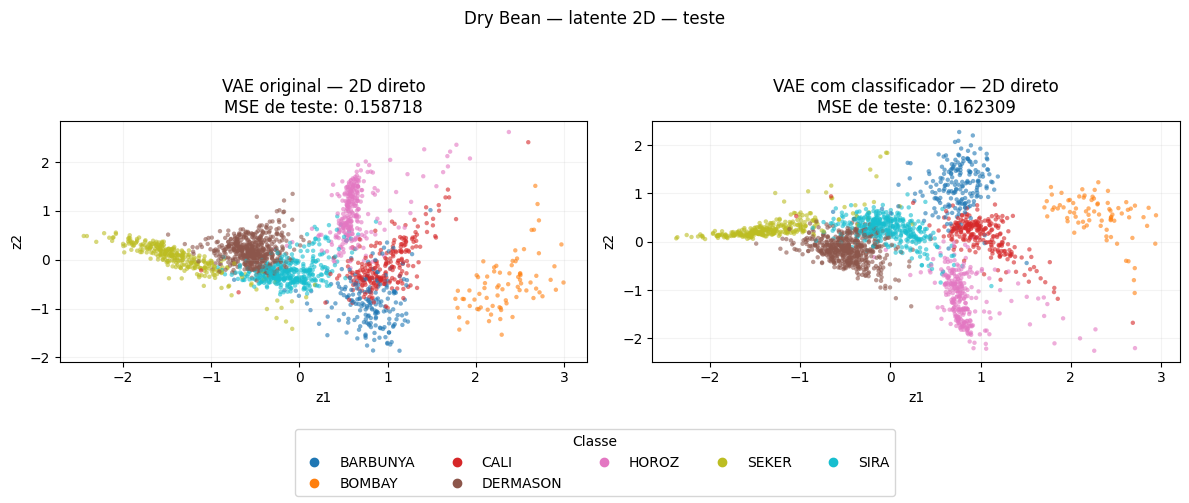

Dry Bean 8D: reutilizando supervisão auxiliar salva.


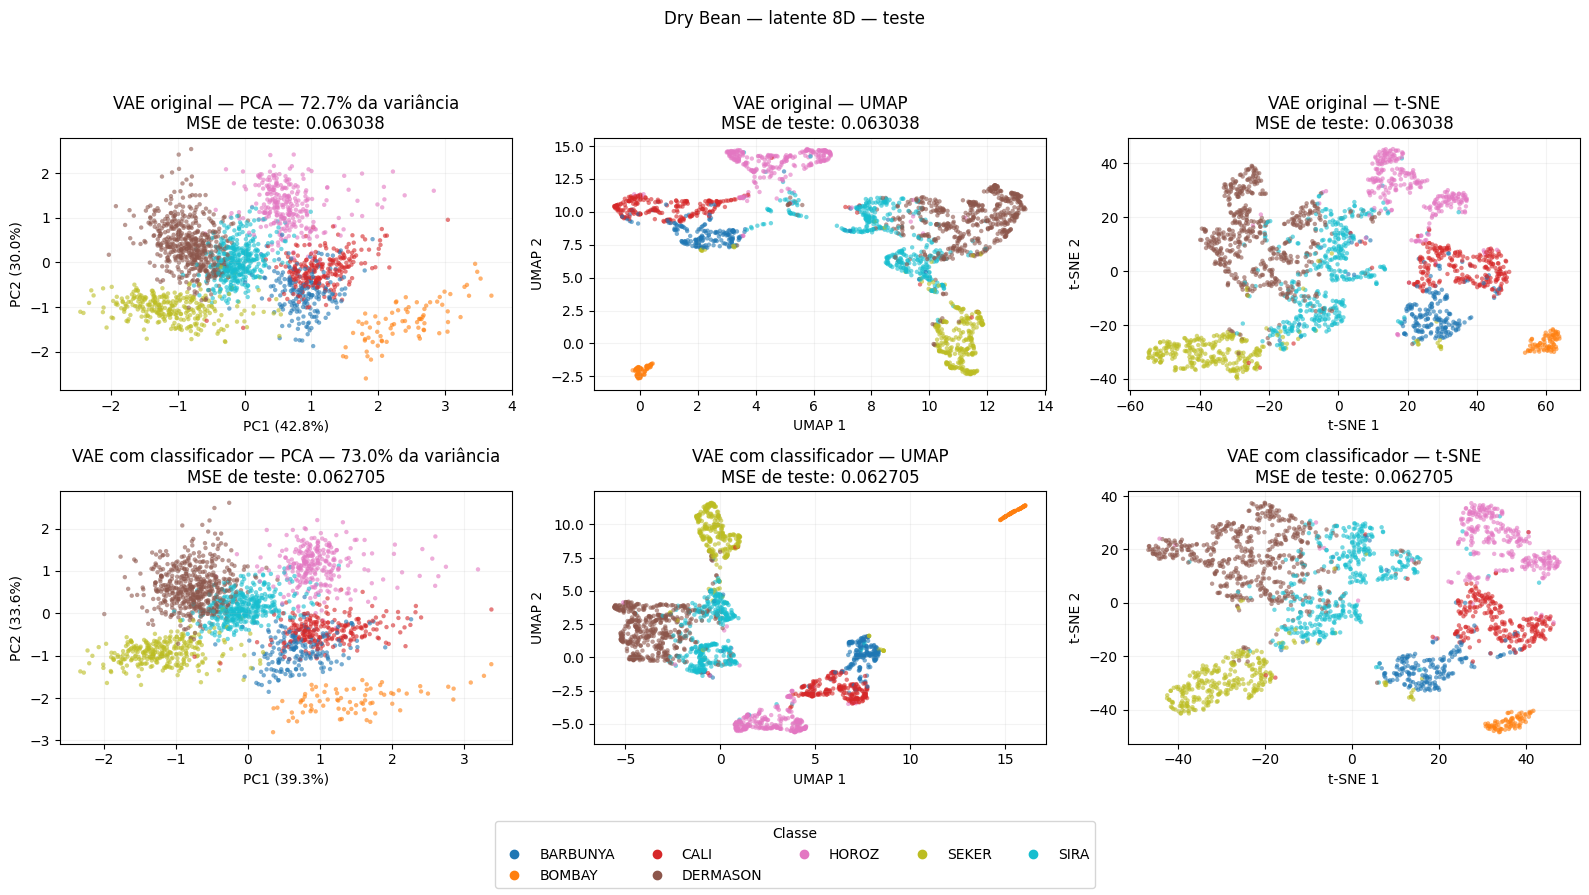

Dry Bean 16D: reutilizando supervisão auxiliar salva.


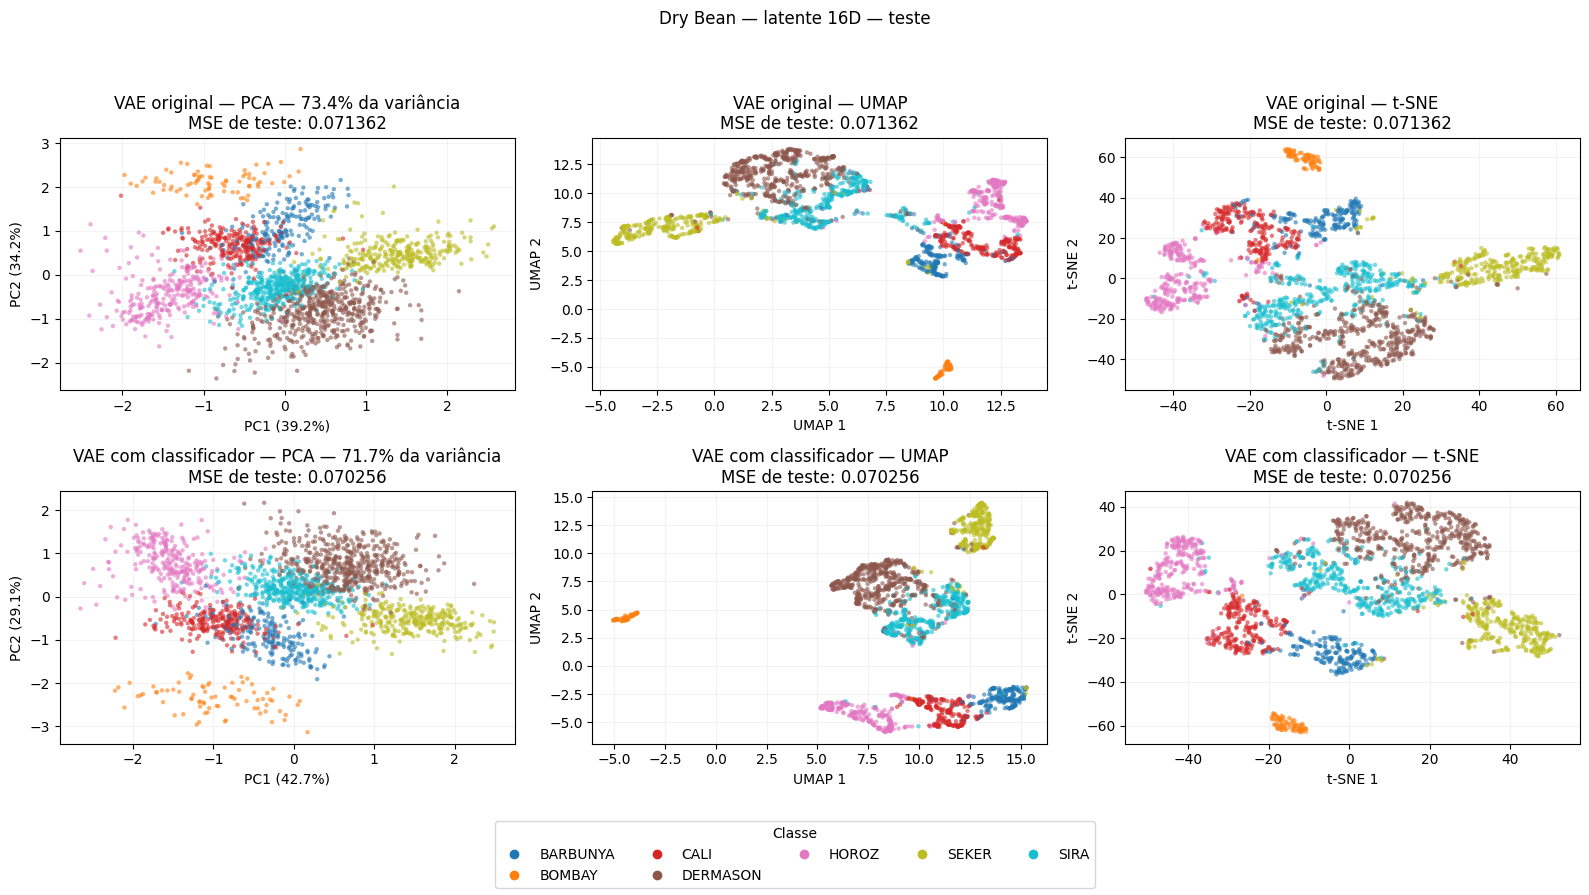

Dry Bean 32D: reutilizando supervisão auxiliar salva.


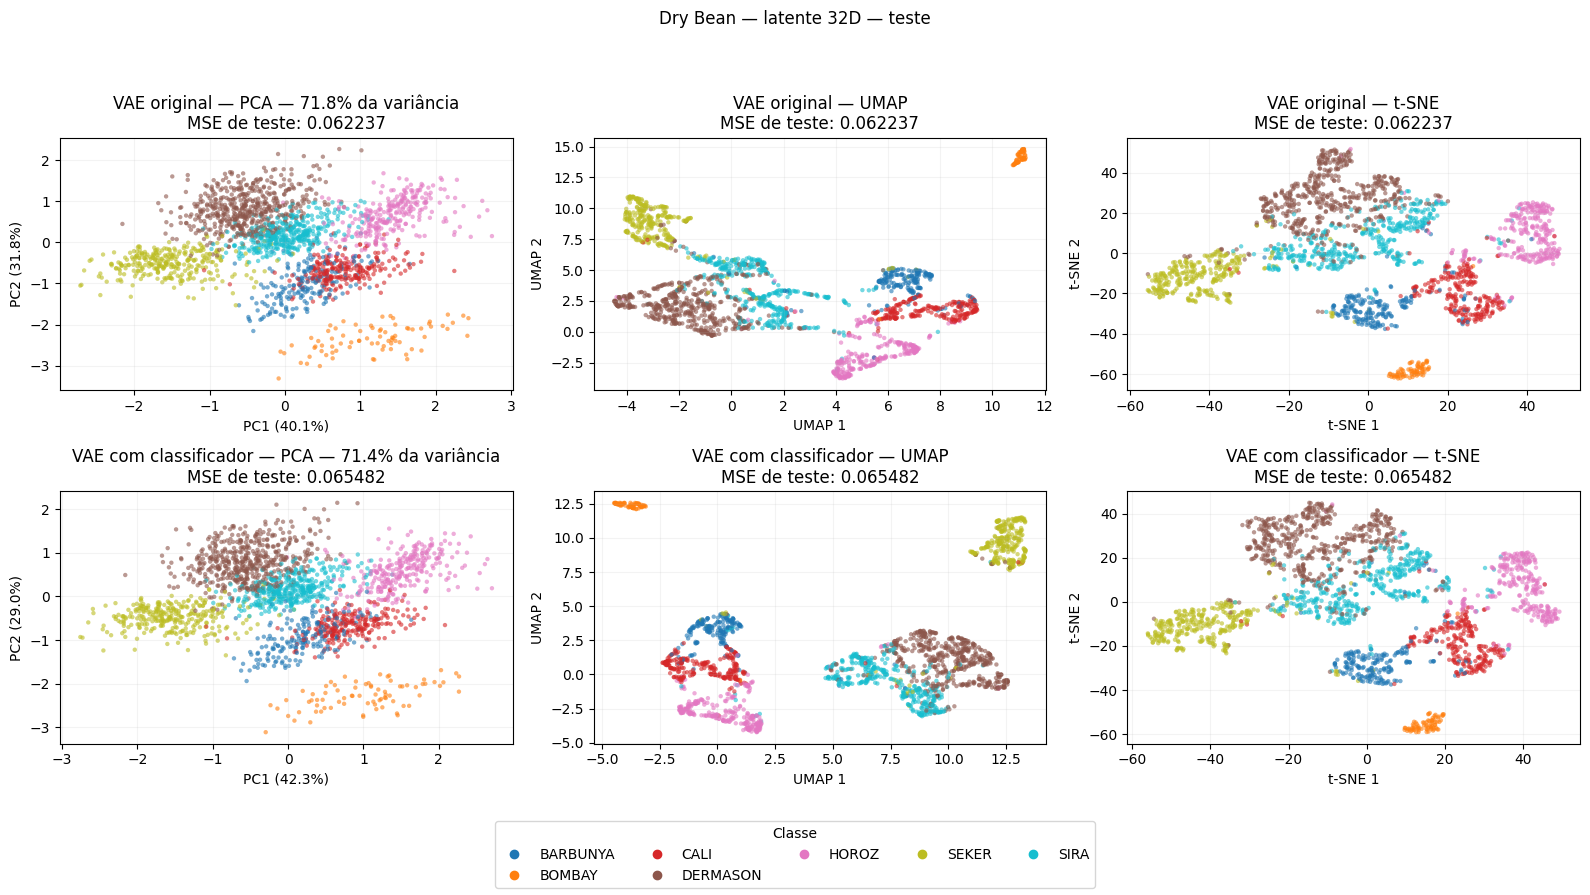

MNIST 2D: reutilizando supervisão auxiliar salva.


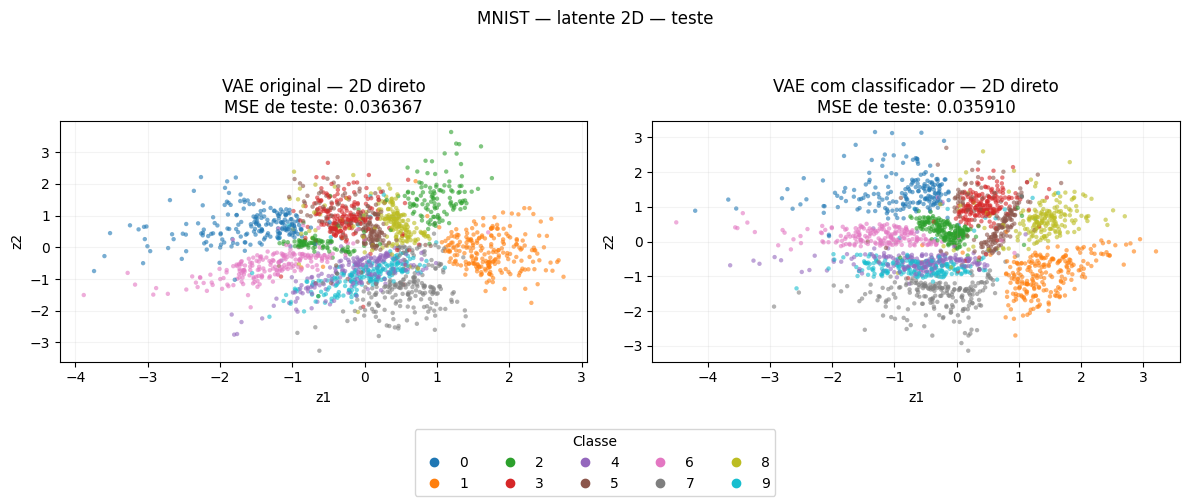

MNIST 8D: reutilizando supervisão auxiliar salva.


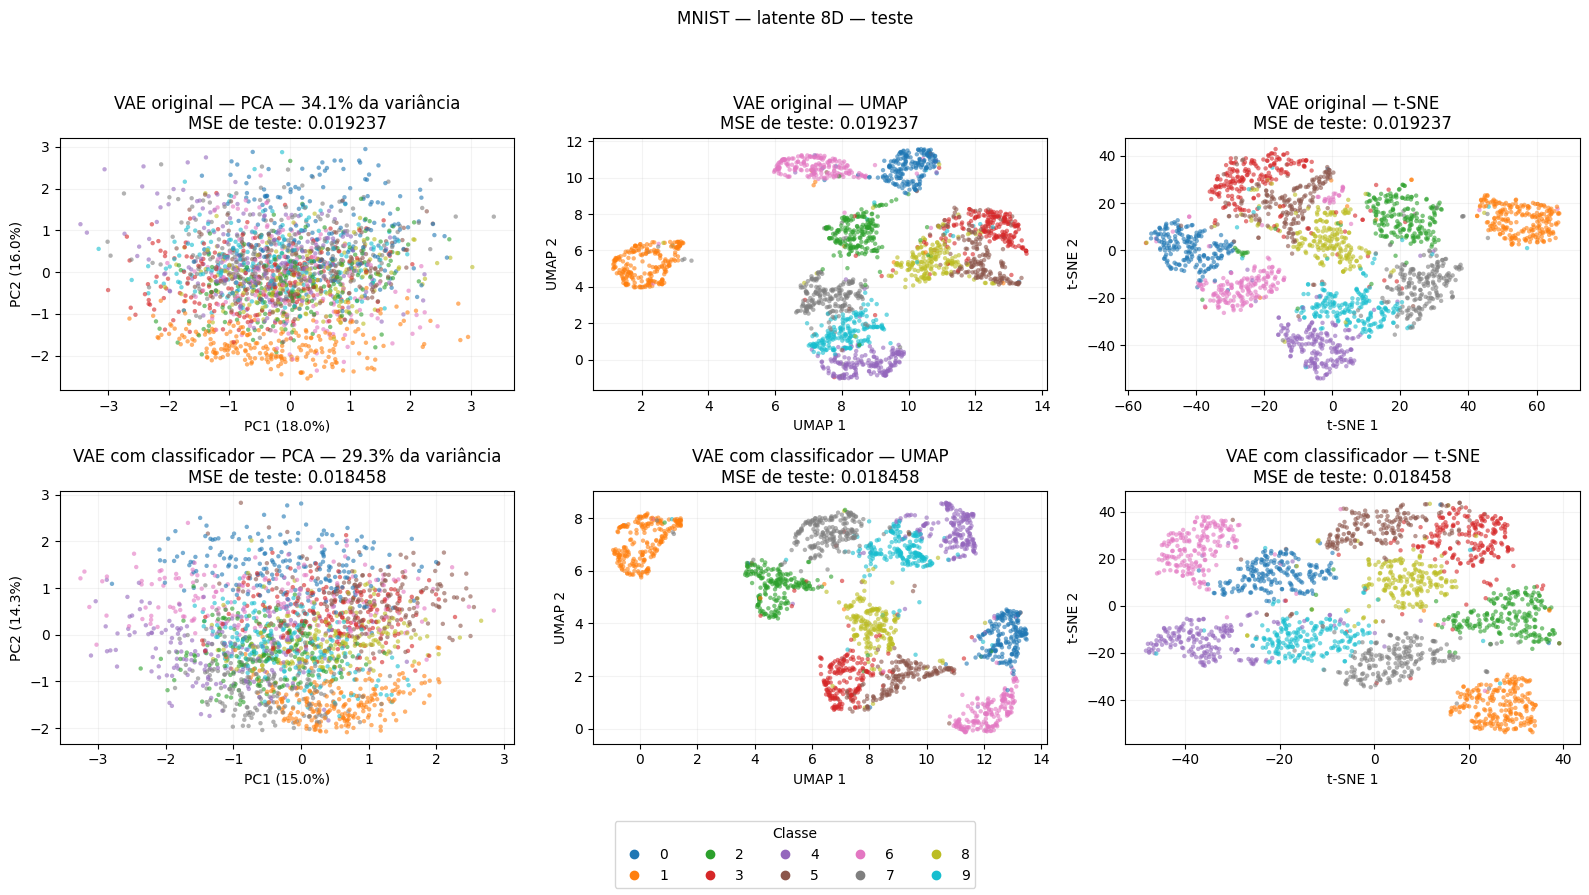

MNIST 16D: reutilizando supervisão auxiliar salva.


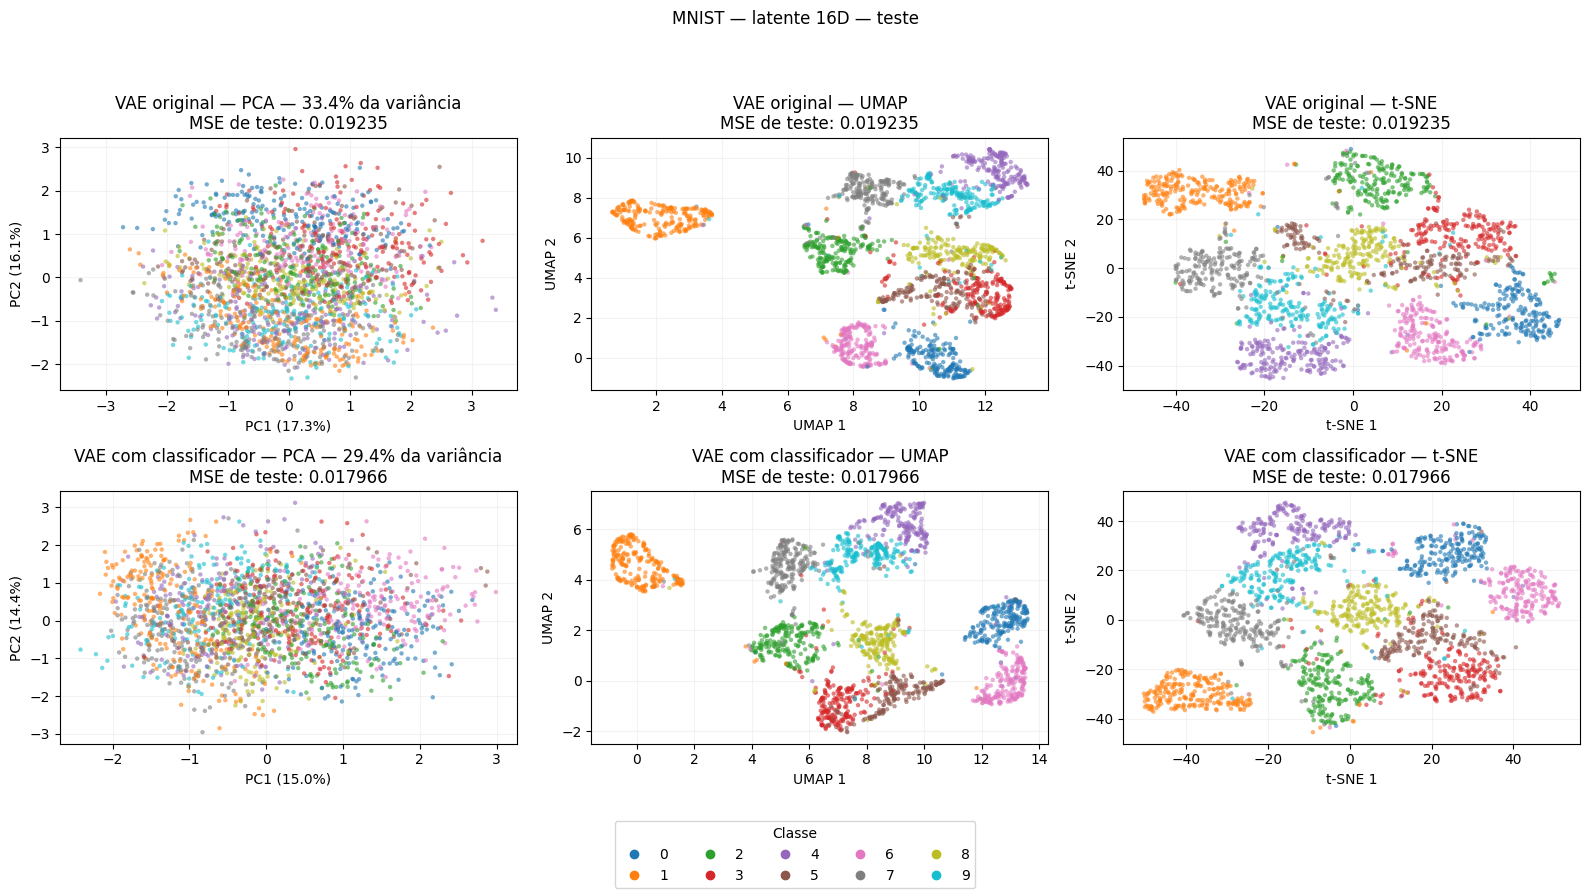

MNIST 32D: reutilizando supervisão auxiliar salva.


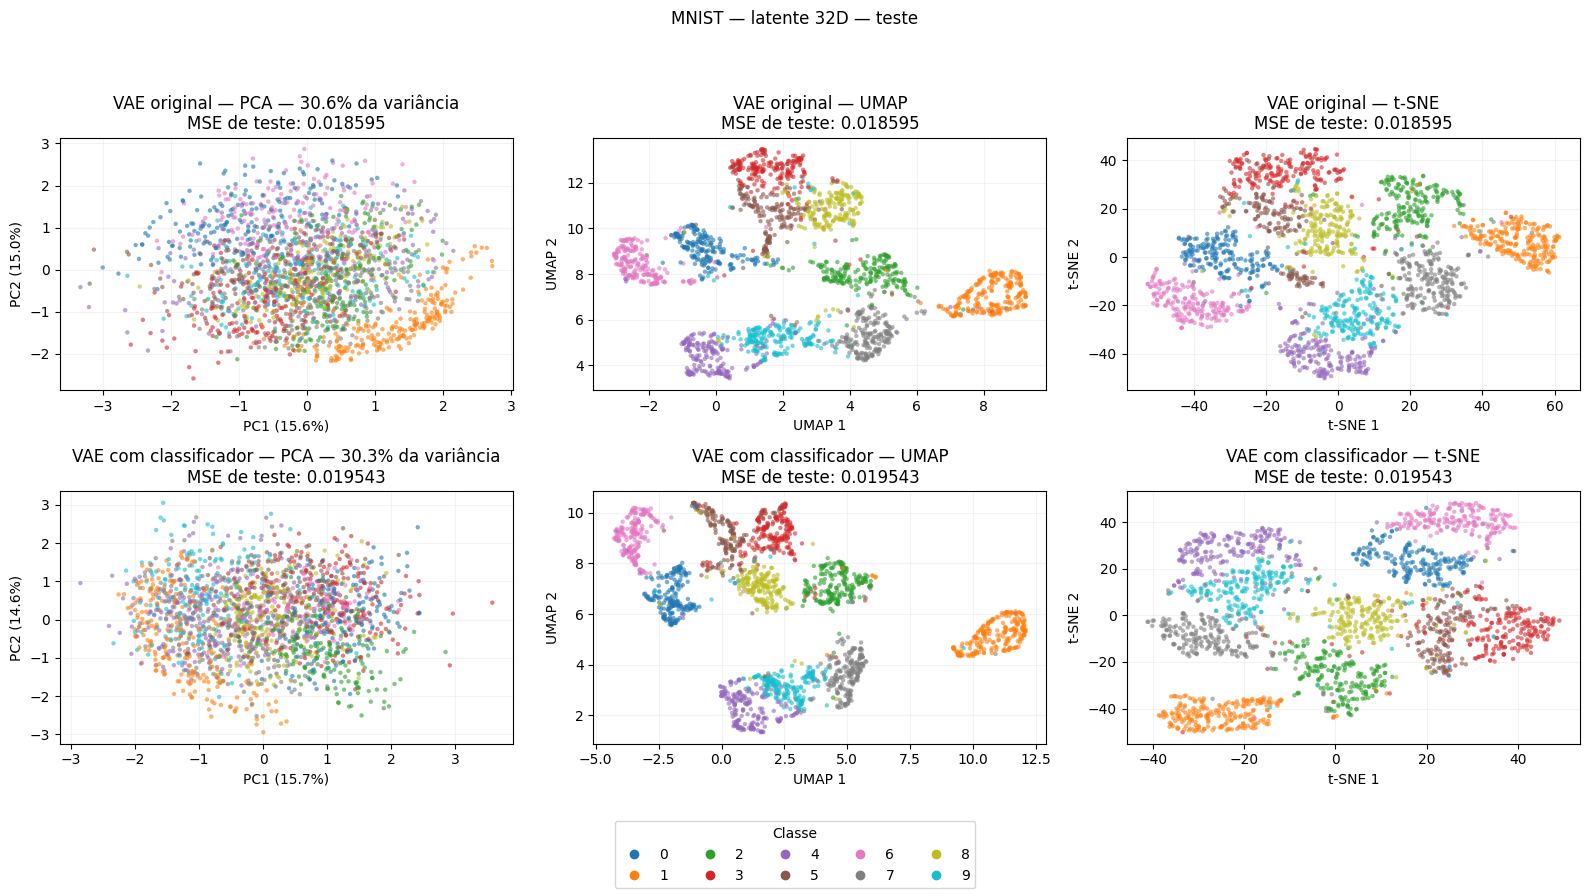

,dataset,latente,MSE_original,MSE_auxiliar
0,Dry Bean,2,0.1587,0.1623
1,Dry Bean,8,0.0630,0.0627
2,Dry Bean,16,0.0714,0.0703
3,Dry Bean,32,0.0622,0.0655
4,MNIST,2,0.0364,0.0359
5,MNIST,8,0.0192,0.0185
6,MNIST,16,0.0192,0.0180
7,MNIST,32,0.0186,0.0195


In [96]:
LAMBDA_AUX = 1.0
RETREINAR_AUX = False
base_aux = DATA_DIR.parents[1] / "results"
pasta_aux = base_aux / "supervisao_auxiliar"
pasta_aux.mkdir(parents=True, exist_ok=True)
dados_aux = {
    "dry_bean": ("Dry Bean", X_dry_train, y_dry_train, X_dry_val, y_dry_val, X_dry_test, y_dry_test),
    "mnist": ("MNIST", X_mnist_train_norm, y_mnist_train_split,
              X_mnist_val_norm, y_mnist_val, X_mnist_test_norm, y_mnist_test),
}
resultados_aux = []
for prefixo, (nome, X_t, y_t, X_v, y_v, X_te, y_te) in dados_aux.items():
    encoder_rotulos = LabelEncoder().fit(y_t)
    yt, yv, yte = [encoder_rotulos.transform(y) for y in (y_t, y_v, y_te)]
    classes = encoder_rotulos.classes_
    #Identifica os dados de treinamento para não reutilizar pesos de outra divisão.
    hashes = [hashlib.sha256(np.ascontiguousarray(a).tobytes()).hexdigest() for a in (X_t, yt, X_v, yv)]
    for dim in (2, 8, 16, 32):
        baseline, config = carregar_melhor_vae(base_aux / "optuna" / f"{prefixo}_{dim}d")
        pasta = pasta_aux / f"{prefixo}_{dim}d"
        pasta.mkdir(parents=True, exist_ok=True)
        assinatura = {"baseline": config, "lambda_aux": LAMBDA_AUX, "classes": classes.tolist(),
                      "hashes_treino_validacao": hashes, "criterio": "val_reconstrucao_mais_kl", "versao": 1}
        arquivo_config = pasta / "configuracao.json"
        salvo = json.loads(arquivo_config.read_text(encoding="utf-8")) if arquivo_config.exists() else {}
        if (not RETREINAR_AUX and salvo.get("assinatura") == assinatura
                and (pasta / "melhor_modelo.pt").exists() and (pasta / "historico.csv").exists()):
            auxiliar = criar_vae(**config["modelo"])
            pesos = torch.load(pasta / "melhor_modelo.pt", map_location="cpu", weights_only=True)
            auxiliar.load_state_dict(pesos["vae"])
            print(f"{nome} {dim}D: reutilizando supervisão auxiliar salva.")
        else:
            if not RETREINAR_AUX:
                raise ValueError(f"{nome} {dim}D: modelo auxiliar salvo ausente ou incompatível; nenhum treino iniciado.")
            print(f"{nome} {dim}D: treinando supervisão auxiliar...")
            auxiliar, pesos, historico, melhor_epoca = treinar_auxiliar(
                config, X_t, yt, X_v, yv, len(classes), LAMBDA_AUX)
            torch.save(pesos, pasta / "melhor_modelo.pt")
            historico.to_csv(pasta / "historico.csv", index=False)
            arquivo_config.write_text(json.dumps({"assinatura": assinatura, "melhor_epoca": melhor_epoca},
                                                indent=2, ensure_ascii=False), encoding="utf-8")
        resultados_aux.append(comparar_auxiliar(baseline, auxiliar, X_t, X_te, yte, classes,
                                              nome, dim, pasta, config["seed"]))
        pd.DataFrame(resultados_aux).to_csv(pasta_aux / "comparacao_resultados.csv", index=False)
        del baseline, auxiliar, pesos

comparacao_aux = pd.DataFrame(resultados_aux)
colunas_aux = ["dataset", "latente", "MSE_original", "MSE_auxiliar"]
display(comparacao_aux[colunas_aux].round(4))

### Conclusão do experimento adicional

Os gráficos desta execução sugerem ganhos pontuais de organização com o classificador, sem uma melhora visual uniforme nas quatro dimensões. No Dry Bean 2D, por exemplo, BARBUNYA e CALI aparecem menos misturadas, embora ainda haja sobreposição entre classes. No MNIST, algumas regiões ficam mais definidas nas projeções não lineares, mas o PCA continua mostrando bastante mistura. **UMAP e t-SNE revelaram agrupamentos no MNIST**, que demonstra uma excelente alternativa ao PCA, que apresentava tudo junto.